In [2]:
#Load the processed Worlds data

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Project root = folder containing data/, notebooks/, etc.
PROJECT_ROOT = Path.cwd().parent

# Load the processed Oracle's Elixir dataset
elixir_df = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" / "worlds_swiss_onward.csv"
)

print("Rows:", len(elixir_df))
print("Columns:", len(elixir_df.columns))

elixir_df.head()

Rows: 864
Columns: 165


,gameid,datacompleteness,url,league,year,split,playoffs,date,game,patch,...,opp_csat25,golddiffat25,xpdiffat25,csdiffat25,killsat25,assistsat25,deathsat25,opp_killsat25,opp_assistsat25,opp_deathsat25
0,LOLTMNT02_482269,complete,NaN,WLDs,2026,NaN,0,2026-10-23 17:21:18,1,16.2,...,209.0,-1155.0,-2725.0,-20.0,1.0,5.0,4.0,1.0,8.0,2.0
1,LOLTMNT02_482269,complete,NaN,WLDs,2026,NaN,0,2026-10-23 17:21:18,1,16.2,...,244.0,-4661.0,-5372.0,-70.0,0.0,7.0,2.0,4.0,10.0,1.0
2,LOLTMNT02_482269,complete,NaN,WLDs,2026,NaN,0,2026-10-23 17:21:18,1,16.2,...,255.0,-3108.0,-3966.0,-39.0,4.0,4.0,4.0,7.0,6.0,1.0
3,LOLTMNT02_482269,complete,NaN,WLDs,2026,NaN,0,2026-10-23 17:21:18,1,16.2,...,235.0,-370.0,-1539.0,18.0,4.0,4.0,1.0,4.0,8.0,2.0
4,LOLTMNT02_482269,complete,NaN,WLDs,2026,NaN,0,2026-10-23 17:21:18,1,16.2,...,29.0,-501.0,-2401.0,0.0,0.0,8.0,5.0,0.0,13.0,3.0


In [3]:
# Keep only team-level rows
team_eda = elixir_df[
    elixir_df["position"] == "team"
].copy()

print("Team rows:", len(team_eda))
print("Unique games:", team_eda["gameid"].nunique())

team_eda.head()

Team rows: 144
Unique games: 72


,gameid,datacompleteness,url,league,year,split,playoffs,date,game,patch,...,opp_csat25,golddiffat25,xpdiffat25,csdiffat25,killsat25,assistsat25,deathsat25,opp_killsat25,opp_assistsat25,opp_deathsat25
10,LOLTMNT02_482269,complete,NaN,WLDs,2026,NaN,0,2026-10-23 17:21:18,1,16.2,...,972.0,-9795.0,-16003.0,-111.0,9.0,28.0,16.0,16.0,45.0,9.0
11,LOLTMNT02_482269,complete,NaN,WLDs,2026,NaN,0,2026-10-23 17:21:18,1,16.2,...,861.0,9795.0,16003.0,111.0,16.0,45.0,9.0,9.0,28.0,16.0
22,LOLTMNT02_483314,complete,NaN,WLDs,2026,NaN,0,2026-10-23 18:23:03,1,16.2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
23,LOLTMNT02_483314,complete,NaN,WLDs,2026,NaN,0,2026-10-23 18:23:03,1,16.2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
34,LOLTMNT02_483342,complete,NaN,WLDs,2026,NaN,0,2026-10-23 19:12:48,1,16.2,...,883.0,1741.0,-294.0,40.0,10.0,23.0,8.0,8.0,18.0,10.0


In [4]:
# Put Blue and Red teams on the same row
eda_games = team_eda.pivot(
    index="gameid",
    columns="side",
    values=[
        "teamname",
        "result",
        "gamelength"
    ]
).reset_index()

# Flatten the column names
eda_games.columns = [
    "_".join(col).strip("_")
    for col in eda_games.columns
]

eda_games.head()

,gameid,teamname_Blue,teamname_Red,result_Blue,result_Red,gamelength_Blue,gamelength_Red
0,LOLTMNT02_482269,Invictus Gaming,Gen.G,0,1,1561,1561
1,LOLTMNT02_482292,Karmine Corp,Anyone's Legend,1,0,1996,1996
2,LOLTMNT02_482304,Dplus Kia,G2 Esports,1,0,1958,1958
3,LOLTMNT02_482313,Team Liquid,CTBC Flying Oyster,0,1,2252,2252
4,LOLTMNT02_482325,LØS,T1,0,1,1466,1466


In [5]:
#name cleaning
eda_games = eda_games.rename(
    columns={
        "teamname_Blue": "blue_team",
        "teamname_Red": "red_team",
        "result_Blue": "blue_result",
        "result_Red": "red_result",
        "gamelength_Blue": "gamelength_seconds"
    }
)

# Game length in minutes
eda_games["gamelength_minutes"] = (
    eda_games["gamelength_seconds"] / 60
)

# Determine which side won
eda_games["winning_side"] = np.where(
    eda_games["blue_result"] == 1,
    "Blue",
    "Red"
)

print("Games:", len(eda_games))

eda_games.head()

Games: 72


,gameid,blue_team,red_team,blue_result,red_result,gamelength_seconds,gamelength_Red,gamelength_minutes,winning_side
0,LOLTMNT02_482269,Invictus Gaming,Gen.G,0,1,1561,1561,26.016667,Red
1,LOLTMNT02_482292,Karmine Corp,Anyone's Legend,1,0,1996,1996,33.266667,Blue
2,LOLTMNT02_482304,Dplus Kia,G2 Esports,1,0,1958,1958,32.633333,Blue
3,LOLTMNT02_482313,Team Liquid,CTBC Flying Oyster,0,1,2252,2252,37.533333,Red
4,LOLTMNT02_482325,LØS,T1,0,1,1466,1466,24.433333,Red


In [6]:
#basic check before eda

print("Unique games:", eda_games["gameid"].nunique())

print("\nWinning side:")
print(eda_games["winning_side"].value_counts())

print("\nMissing values:")
print(
    eda_games[
        [
            "blue_team",
            "red_team",
            "blue_result",
            "red_result",
            "gamelength_seconds",
            "winning_side"
        ]
    ].isna().sum()
)

Unique games: 72

Winning side:
winning_side
Blue    41
Red     31
Name: count, dtype: int64

Missing values:
blue_team             0
red_team              0
blue_result           0
red_result            0
gamelength_seconds    0
winning_side          0
dtype: int64


object
Missing game lengths: 0


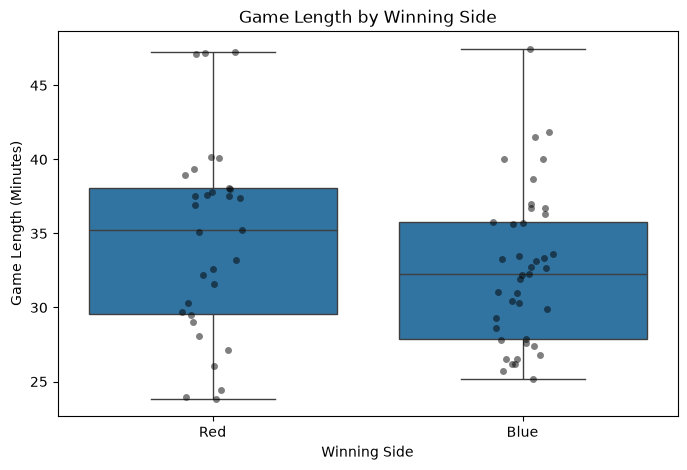

In [7]:
# Is the length of games different depening on which side wins?

# Check the data type
print(eda_games["gamelength_minutes"].dtype)

# Convert game length to numeric
eda_games["gamelength_minutes"] = pd.to_numeric(
    eda_games["gamelength_minutes"],
    errors="coerce"
)

# Check for values that couldn't be converted
print("Missing game lengths:", eda_games["gamelength_minutes"].isna().sum())


# Summary of game length by winning side

game_length_summary = eda_games.groupby("winning_side")[
    "gamelength_minutes"
].describe()

game_length_summary

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=eda_games,
    x="winning_side",
    y="gamelength_minutes"
)

sns.stripplot(
    data=eda_games,
    x="winning_side",
    y="gamelength_minutes",
    color="black",
    alpha=0.5
)

plt.xlabel("Winning Side")
plt.ylabel("Game Length (Minutes)")
plt.title("Game Length by Winning Side")

plt.show()


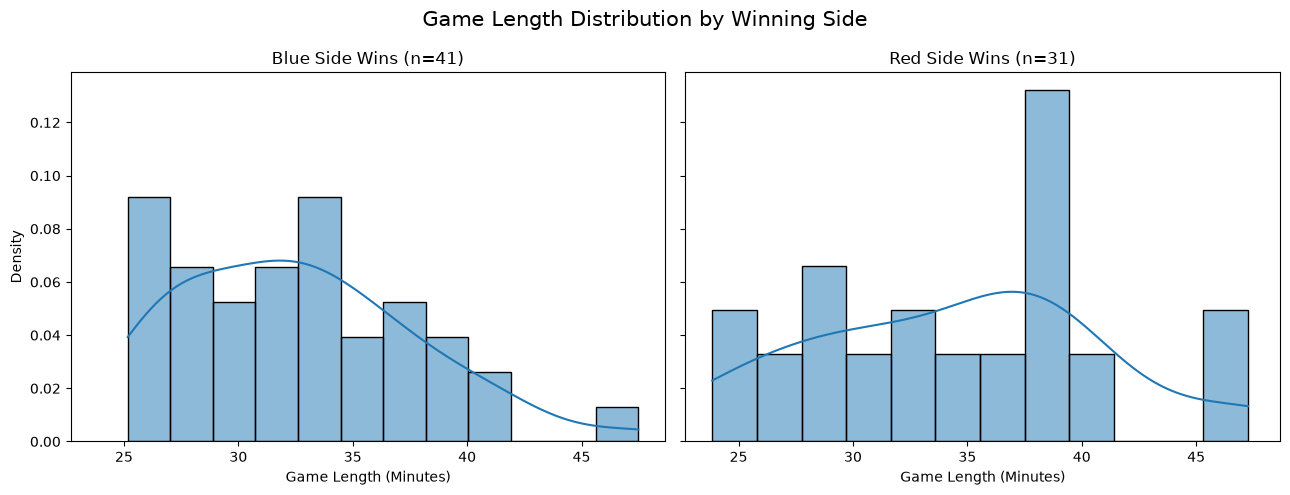

In [8]:
#Check disrtibution of winning side game length

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)

for ax, side in zip(axes, ["Blue", "Red"]):

    side_data = eda_games.loc[
        eda_games["winning_side"] == side,
        "gamelength_minutes"
    ].dropna()

    sns.histplot(
        side_data,
        bins=12,
        kde=True,
        stat="density",
        ax=ax
    )

    ax.set_title(f"{side} Side Wins (n={len(side_data)})")
    ax.set_xlabel("Game Length (Minutes)")
    ax.set_ylabel("Density")

fig.suptitle("Game Length Distribution by Winning Side", fontsize=15)
plt.tight_layout()
plt.show()

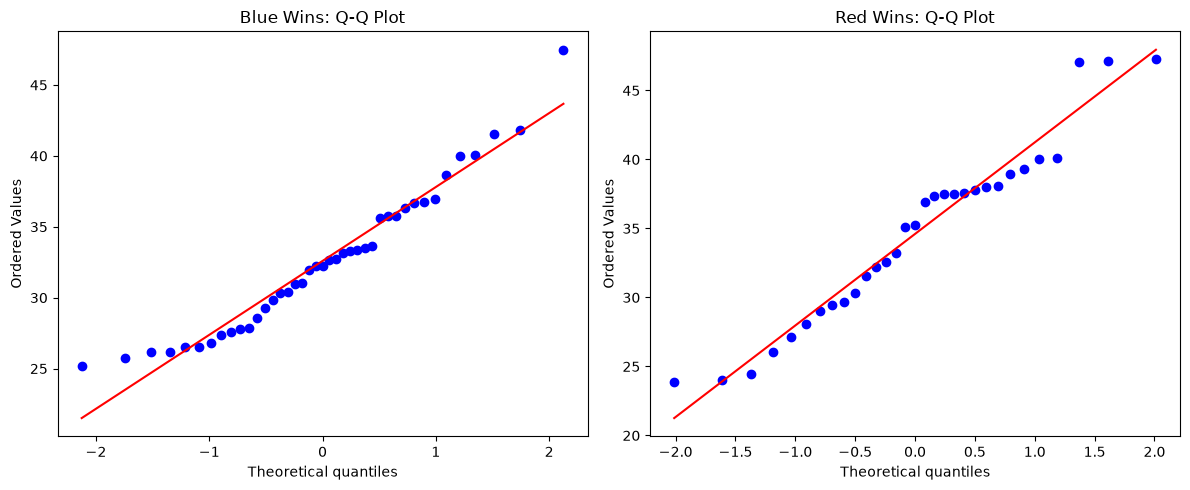

In [9]:
from scipy import stats

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, side in zip(axes, ["Blue", "Red"]):
    values = eda_games.loc[
        eda_games["winning_side"] == side,
        "gamelength_minutes"
    ].dropna()

    stats.probplot(
        values,
        dist="norm",
        plot=ax
    )

    ax.set_title(f"{side} Wins: Q-Q Plot")

plt.tight_layout()
plt.show()

In [10]:
distribution_summary = eda_games.groupby("winning_side")[
    "gamelength_minutes"
].agg(
    ["count", "mean", "median", "std", "min", "max", "skew"]
)

distribution_summary

,count,mean,median,std,min,max,skew
winning_side,,,,,,,
Blue,41,32.592276,32.25,5.179715,25.166667,47.483333,0.697336
Red,31,34.605914,35.25,6.514922,23.850000,47.266667,0.169731


In [11]:
#Test of signifigance

# Mann-whitney U test for differences in distribution, Welch t-test assess a difference in means
# We don't expect the game length to have equal variance
# We don't expect normally distributed games (we should check that as well)

from scipy.stats import ttest_ind, mannwhitneyu

blue_wins = eda_games.loc[
    eda_games["winning_side"] == "Blue",
    "gamelength_minutes"
].dropna()

red_wins = eda_games.loc[
    eda_games["winning_side"] == "Red",
    "gamelength_minutes"
].dropna()

# Welch's independent two-sample t-test
t_stat, t_pvalue = ttest_ind(
    blue_wins,
    red_wins,
    equal_var=False
)

# Mann-Whitney U test
u_stat, u_pvalue = mannwhitneyu(
    blue_wins,
    red_wins,
    alternative="two-sided"
)

print("Welch's t-test")
print(f"t-statistic: {t_stat:.4f}")
print(f"p-value: {t_pvalue:.4f}")

print("\nMann-Whitney U test")
print(f"U-statistic: {u_stat:.2f}")
print(f"p-value: {u_pvalue:.4f}")

Welch's t-test
t-statistic: -1.4155
p-value: 0.1625

Mann-Whitney U test
U-statistic: 513.00
p-value: 0.1653


In [12]:
#Gold and xp differences between red and blue

# Keep only team-level rows
team_data = elixir_df[
    elixir_df["position"] == "team"
].copy()

print("Team rows:", len(team_data))
print("Unique games:", team_data["gameid"].nunique())
gold_diff_columns = [
    "golddiffat10",
    "golddiffat15",
    "golddiffat20",
    "golddiffat25"
]

xp_diff_columns = [
    "xpdiffat10",
    "xpdiffat15",
    "xpdiffat20",
    "xpdiffat25"
]

print(team_data[
    ["gameid", "teamname", "side"] +
    gold_diff_columns +
    xp_diff_columns
].head(10))

# Identify available difference columns
diff_columns = [
    col for col in elixir_df.columns
    if "diffat" in col.lower()
]

print(diff_columns)

Team rows: 144
Unique games: 72
              gameid             teamname  side  golddiffat10  golddiffat15  \
10  LOLTMNT02_482269      Invictus Gaming  Blue        1859.0        1892.0   
11  LOLTMNT02_482269                Gen.G   Red       -1859.0       -1892.0   
22  LOLTMNT02_483314          Top Esports  Blue       -1289.0        -943.0   
23  LOLTMNT02_483314  Hanwha Life Esports   Red        1289.0         943.0   
34  LOLTMNT02_483342         Movistar KOI  Blue        1600.0        1088.0   
35  LOLTMNT02_483342      Bilibili Gaming   Red       -1600.0       -1088.0   
46  LOLTMNT02_482292         Karmine Corp  Blue        -724.0        -461.0   
47  LOLTMNT02_482292      Anyone's Legend   Red         724.0         461.0   
58  LOLTMNT02_482304            Dplus Kia  Blue        -993.0       -2185.0   
59  LOLTMNT02_482304           G2 Esports   Red         993.0        2185.0   

    golddiffat20  golddiffat25  xpdiffat10  xpdiffat15  xpdiffat20  xpdiffat25  
10       -2574.0 

In [13]:
team_data[
    ["gameid", "teamname", "side"] + diff_columns
].head(10)

,gameid,teamname,side,golddiffat10,xpdiffat10,csdiffat10,golddiffat15,xpdiffat15,csdiffat15,golddiffat20,xpdiffat20,csdiffat20,golddiffat25,xpdiffat25,csdiffat25
10,LOLTMNT02_482269,Invictus Gaming,Blue,1859.0,286.0,-2.0,1892.0,-122.0,-5.0,-2574.0,-5483.0,-62.0,-9795.0,-16003.0,-111.0
11,LOLTMNT02_482269,Gen.G,Red,-1859.0,-286.0,2.0,-1892.0,122.0,5.0,2574.0,5483.0,62.0,9795.0,16003.0,111.0
22,LOLTMNT02_483314,Top Esports,Blue,-1289.0,-235.0,3.0,-943.0,-1525.0,-48.0,-8867.0,-8939.0,-86.0,NaN,NaN,NaN
23,LOLTMNT02_483314,Hanwha Life Esports,Red,1289.0,235.0,-3.0,943.0,1525.0,48.0,8867.0,8939.0,86.0,NaN,NaN,NaN
34,LOLTMNT02_483342,Movistar KOI,Blue,1600.0,432.0,17.0,1088.0,-1031.0,18.0,2552.0,414.0,46.0,1741.0,-294.0,40.0
35,LOLTMNT02_483342,Bilibili Gaming,Red,-1600.0,-432.0,-17.0,-1088.0,1031.0,-18.0,-2552.0,-414.0,-46.0,-1741.0,294.0,-40.0
46,LOLTMNT02_482292,Karmine Corp,Blue,-724.0,-824.0,-4.0,-461.0,775.0,20.0,189.0,1144.0,32.0,1992.0,6220.0,53.0
47,LOLTMNT02_482292,Anyone's Legend,Red,724.0,824.0,4.0,461.0,-775.0,-20.0,-189.0,-1144.0,-32.0,-1992.0,-6220.0,-53.0
58,LOLTMNT02_482304,Dplus Kia,Blue,-993.0,1459.0,49.0,-2185.0,1467.0,51.0,-3319.0,476.0,83.0,-2809.0,1711.0,109.0
59,LOLTMNT02_482304,G2 Esports,Red,993.0,-1459.0,-49.0,2185.0,-1467.0,-51.0,3319.0,-476.0,-83.0,2809.0,-1711.0,-109.0


In [14]:
# Select the gold and XP difference columns
gold_diff_columns = [
    "golddiffat10",
    "golddiffat15",
    "golddiffat20",
    "golddiffat25"
]

xp_diff_columns = [
    "xpdiffat10",
    "xpdiffat15",
    "xpdiffat20",
    "xpdiffat25"
]

# Keep only Blue team rows: one observation per game
blue_advantage = team_data.loc[
    team_data["side"] == "Blue",
    ["gameid"] + gold_diff_columns + xp_diff_columns
].copy()

# Check the resulting dataset
print("Number of games:", len(blue_advantage))
print("Unique games:", blue_advantage["gameid"].nunique())

print("\nMissing values:")
print(blue_advantage[gold_diff_columns + xp_diff_columns].isna().sum())

display(blue_advantage.head())

Number of games: 72
Unique games: 72

Missing values:
golddiffat10    0
golddiffat15    0
golddiffat20    0
golddiffat25    2
xpdiffat10      0
xpdiffat15      0
xpdiffat20      0
xpdiffat25      2
dtype: int64


,gameid,golddiffat10,golddiffat15,golddiffat20,golddiffat25,xpdiffat10,xpdiffat15,xpdiffat20,xpdiffat25
10,LOLTMNT02_482269,1859.0,1892.0,-2574.0,-9795.0,286.0,-122.0,-5483.0,-16003.0
22,LOLTMNT02_483314,-1289.0,-943.0,-8867.0,NaN,-235.0,-1525.0,-8939.0,NaN
34,LOLTMNT02_483342,1600.0,1088.0,2552.0,1741.0,432.0,-1031.0,414.0,-294.0
46,LOLTMNT02_482292,-724.0,-461.0,189.0,1992.0,-824.0,775.0,1144.0,6220.0
58,LOLTMNT02_482304,-993.0,-2185.0,-3319.0,-2809.0,1459.0,1467.0,476.0,1711.0


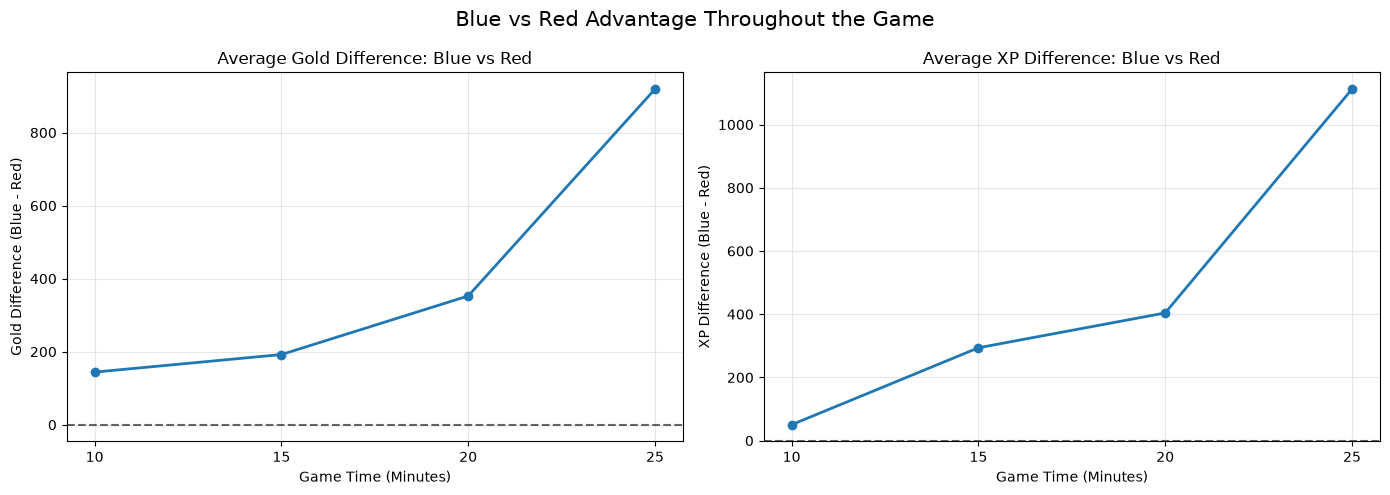

In [15]:
# Calculate average Blue-minus-Red differences at each timestamp
gold_means = blue_advantage[gold_diff_columns].mean()
xp_means = blue_advantage[xp_diff_columns].mean()

# Use game time as the x-axis
game_times = [10, 15, 20, 25]

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gold difference
axes[0].plot(
    game_times,
    gold_means.values,
    marker="o",
    linewidth=2
)

axes[0].axhline(0, color="black", linestyle="--", alpha=0.6)
axes[0].set_title("Average Gold Difference: Blue vs Red")
axes[0].set_xlabel("Game Time (Minutes)")
axes[0].set_ylabel("Gold Difference (Blue - Red)")
axes[0].set_xticks(game_times)
axes[0].grid(alpha=0.3)

# XP difference
axes[1].plot(
    game_times,
    xp_means.values,
    marker="o",
    linewidth=2
)

axes[1].axhline(0, color="black", linestyle="--", alpha=0.6)
axes[1].set_title("Average XP Difference: Blue vs Red")
axes[1].set_xlabel("Game Time (Minutes)")
axes[1].set_ylabel("XP Difference (Blue - Red)")
axes[1].set_xticks(game_times)
axes[1].grid(alpha=0.3)

fig.suptitle("Blue vs Red Advantage Throughout the Game", fontsize=15)
plt.tight_layout()
plt.show()

In [16]:
#I want to look at total xp for each role on red vs blue side and see if there is a significant difference

# Keep player-level rows (exclude team summaries)
player_xp = elixir_df[
    elixir_df["position"] != "team"
].copy()

# Standardize role names
role_names = {
    "top": "Top",
    "jng": "Jungle",
    "jgl": "Jungle",
    "mid": "Mid",
    "bot": "ADC",
    "sup": "Support"
}

player_xp["role"] = player_xp["position"].str.lower().map(role_names)

# XP snapshots
xp_columns = [
    "xpat10",
    "xpat15",
    "xpat20",
    "xpat25"
]

roles = ["ADC", "Jungle", "Top", "Mid", "Support"]

# Check how many observations we have per role and side
display(
    player_xp.groupby(["role", "side"])["gameid"]
    .count()
    .unstack()
    .reindex(roles)
)

# Check for missing XP values
print("\nMissing XP observations:")
print(player_xp.groupby("role")[xp_columns].apply(
    lambda x: x.isna().sum()
).reindex(roles))

side,Blue,Red
role,,
ADC,72,72
Jungle,72,72
Top,72,72
Mid,72,72
Support,72,72



Missing XP observations:
         xpat10  xpat15  xpat20  xpat25
role                                   
ADC           0       0       0       4
Jungle        0       0       0       4
Top           0       0       0       4
Mid           0       0       0       4
Support       0       0       0       4


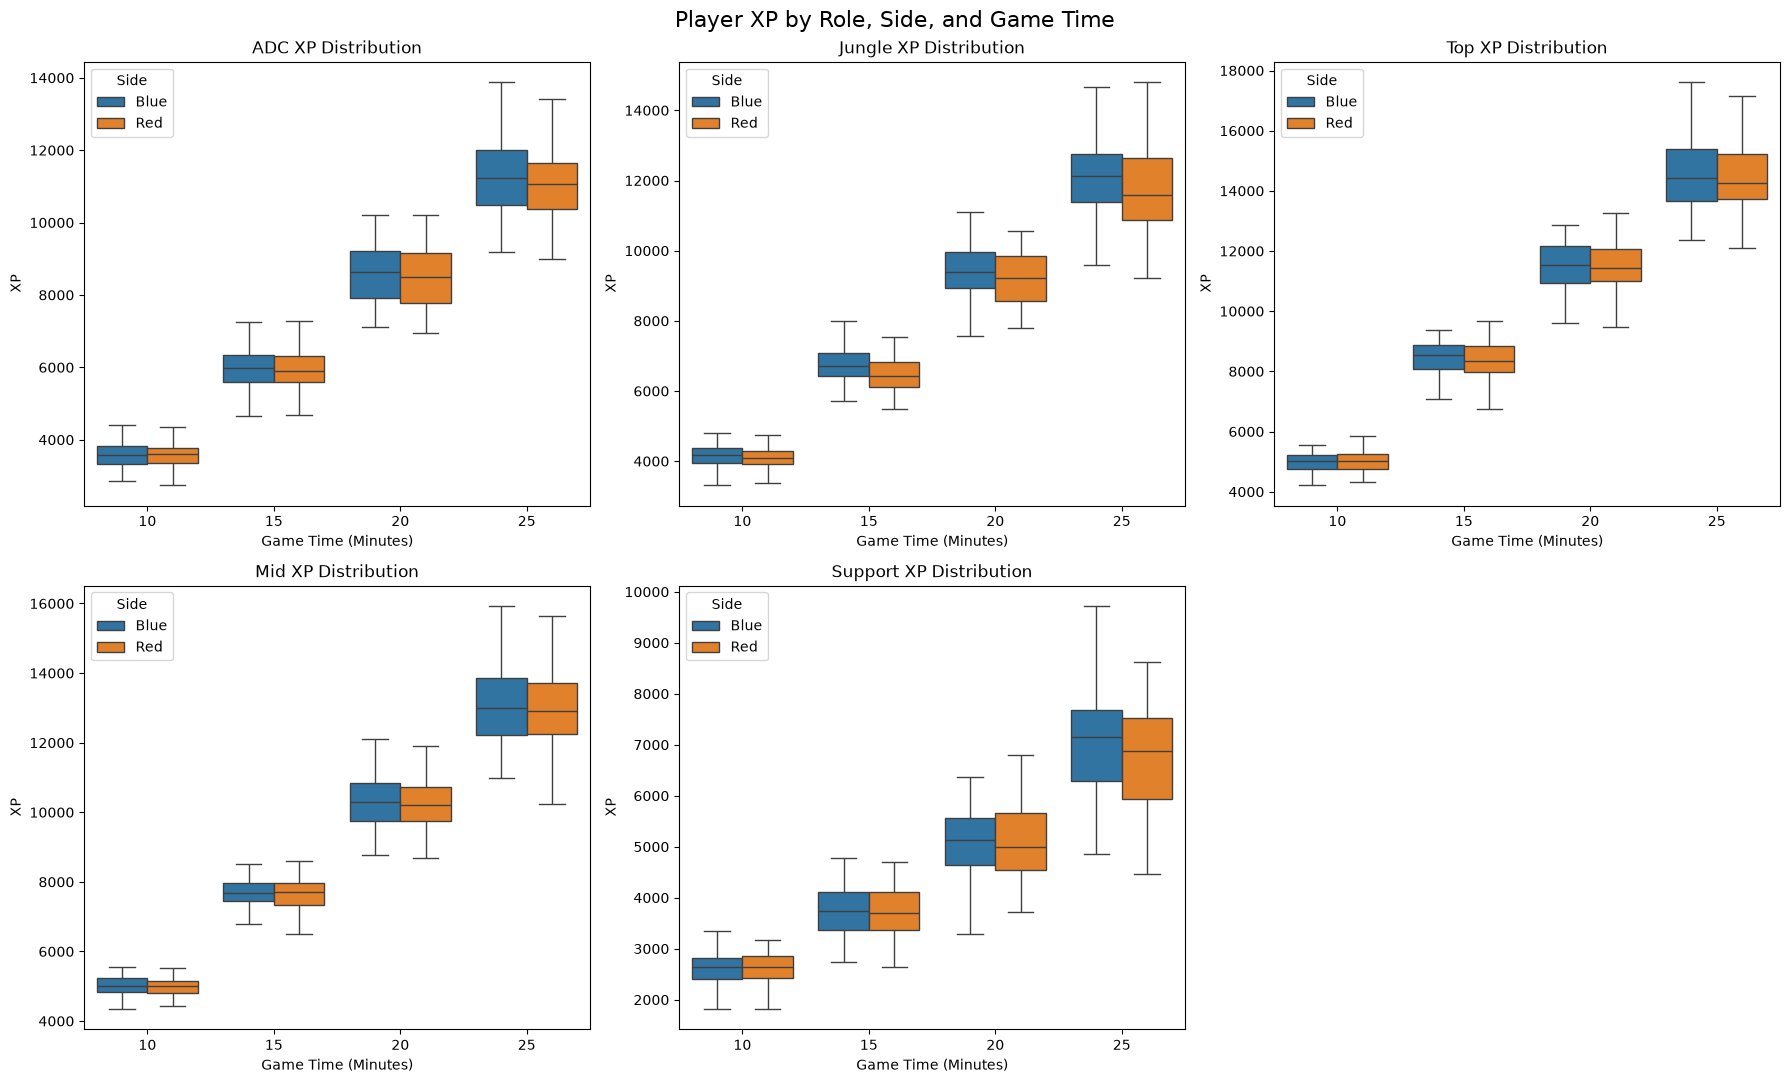

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for i, role in enumerate(roles):
    role_data = player_xp[player_xp["role"] == role].copy()

    role_long = role_data.melt(
        id_vars=["side"],
        value_vars=xp_columns,
        var_name="game_time",
        value_name="XP"
    )

    role_long["game_time"] = role_long["game_time"].map({
        "xpat10": "10",
        "xpat15": "15",
        "xpat20": "20",
        "xpat25": "25"
    })

    sns.boxplot(
        data=role_long,
        x="game_time",
        y="XP",
        hue="side",
        order=["10", "15", "20", "25"],
        hue_order=["Blue", "Red"],
        showfliers=False,
        ax=axes[i]
    )

    axes[i].set_title(f"{role} XP Distribution")
    axes[i].set_xlabel("Game Time (Minutes)")
    axes[i].set_ylabel("XP")
    axes[i].legend(title="Side")

fig.delaxes(axes[5])

fig.suptitle(
    "Player XP by Role, Side, and Game Time",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [18]:
#paired t-test for each role and timestamp
from scipy.stats import ttest_rel, wilcoxon
from statsmodels.stats.multitest import multipletests

results = []

for role in roles:
    role_data = player_xp[player_xp["role"] == role].copy()

    for xp_col in xp_columns:

        # Separate Blue and Red XP, indexed by game
        blue = (
            role_data[role_data["side"] == "Blue"]
            .set_index("gameid")[xp_col]
        )

        red = (
            role_data[role_data["side"] == "Red"]
            .set_index("gameid")[xp_col]
        )

        # Align observations by game and remove missing values
        paired = pd.concat(
            [blue.rename("Blue"), red.rename("Red")],
            axis=1
        ).dropna()

        blue_xp = paired["Blue"]
        red_xp = paired["Red"]

        # Difference: positive means Blue has more XP
        differences = blue_xp - red_xp

        # Paired t-test
        t_stat, t_pvalue = ttest_rel(
            blue_xp,
            red_xp
        )

        # Wilcoxon signed-rank test
        if (differences != 0).any():
            w_stat, w_pvalue = wilcoxon(
                differences,
                alternative="two-sided"
            )
        else:
            w_stat, w_pvalue = 0, 1.0

        results.append({
            "role": role,
            "snapshot": xp_col.replace("xpat", "") + " min",
            "n_games": len(paired),
            "blue_mean_xp": blue_xp.mean(),
            "red_mean_xp": red_xp.mean(),
            "mean_difference": differences.mean(),
            "t_statistic": t_stat,
            "t_pvalue": t_pvalue,
            "wilcoxon_pvalue": w_pvalue
        })

results_df = pd.DataFrame(results)

# Correct the 20 t-test p-values for multiple comparisons
results_df["t_pvalue_holm"] = multipletests(
    results_df["t_pvalue"],
    method="holm"
)[1]

# Correct the 20 Wilcoxon p-values as well
results_df["wilcoxon_pvalue_holm"] = multipletests(
    results_df["wilcoxon_pvalue"],
    method="holm"
)[1]

# Mark statistically significant results
results_df["significant_ttest"] = (
    results_df["t_pvalue_holm"] < 0.05
)

results_df["significant_wilcoxon"] = (
    results_df["wilcoxon_pvalue_holm"] < 0.05
)

display(
    results_df.round(4)
)

,role,snapshot,n_games,blue_mean_xp,red_mean_xp,mean_difference,t_statistic,t_pvalue,wilcoxon_pvalue,t_pvalue_holm,wilcoxon_pvalue_holm,significant_ttest,significant_wilcoxon
0,ADC,10 min,72,3597.5972,3581.2083,16.3889,0.2922,0.7710,0.8333,1.0000,1.0000,False,False
1,ADC,15 min,72,5978.5694,5946.1667,32.4028,0.3749,0.7089,0.7941,1.0000,1.0000,False,False
2,ADC,20 min,72,8581.6944,8524.5556,57.1389,0.5334,0.5954,0.5940,1.0000,1.0000,False,False
3,ADC,25 min,70,11288.5286,11016.2286,272.3000,1.7750,0.0803,0.0995,1.0000,1.0000,False,False
4,Jungle,10 min,72,4156.0417,4087.7917,68.2500,1.4983,0.1385,0.1422,1.0000,1.0000,False,False
5,Jungle,15 min,72,6768.0417,6503.9444,264.0972,2.8471,0.0058,0.0101,0.1153,0.2017,False,False
6,Jungle,20 min,72,9429.5694,9218.2778,211.2917,1.3027,0.1969,0.2364,1.0000,1.0000,False,False
7,Jungle,25 min,70,12140.9286,11753.8571,387.0714,1.4772,0.1442,0.1114,1.0000,1.0000,False,False
8,Top,10 min,72,4959.1944,4985.9306,-26.7361,-0.5138,0.6090,0.5099,1.0000,1.0000,False,False
9,Top,15 min,72,8390.6806,8370.5972,20.0833,0.1932,0.8474,0.7342,1.0000,1.0000,False,False


In [19]:
# Attach the winning side to each game
player_xp_outcome = player_xp.merge(
    eda_games[["gameid", "winning_side"]],
    on="gameid",
    how="left",
    validate="many_to_one"
)

# Check the number of observations
print("Missing winning sides:", player_xp_outcome["winning_side"].isna().sum())

display(
    player_xp_outcome.groupby(
        ["winning_side", "role", "side"]
    )["gameid"].count().unstack()
)

Missing winning sides: 0


side                  Blue  Red
winning_side role              
Blue         ADC        41   41
             Jungle     41   41
             Mid        41   41
             Support    41   41
             Top        41   41
Red          ADC        31   31
             Jungle     31   31
             Mid        31   31
             Support    31   31
             Top        31   31

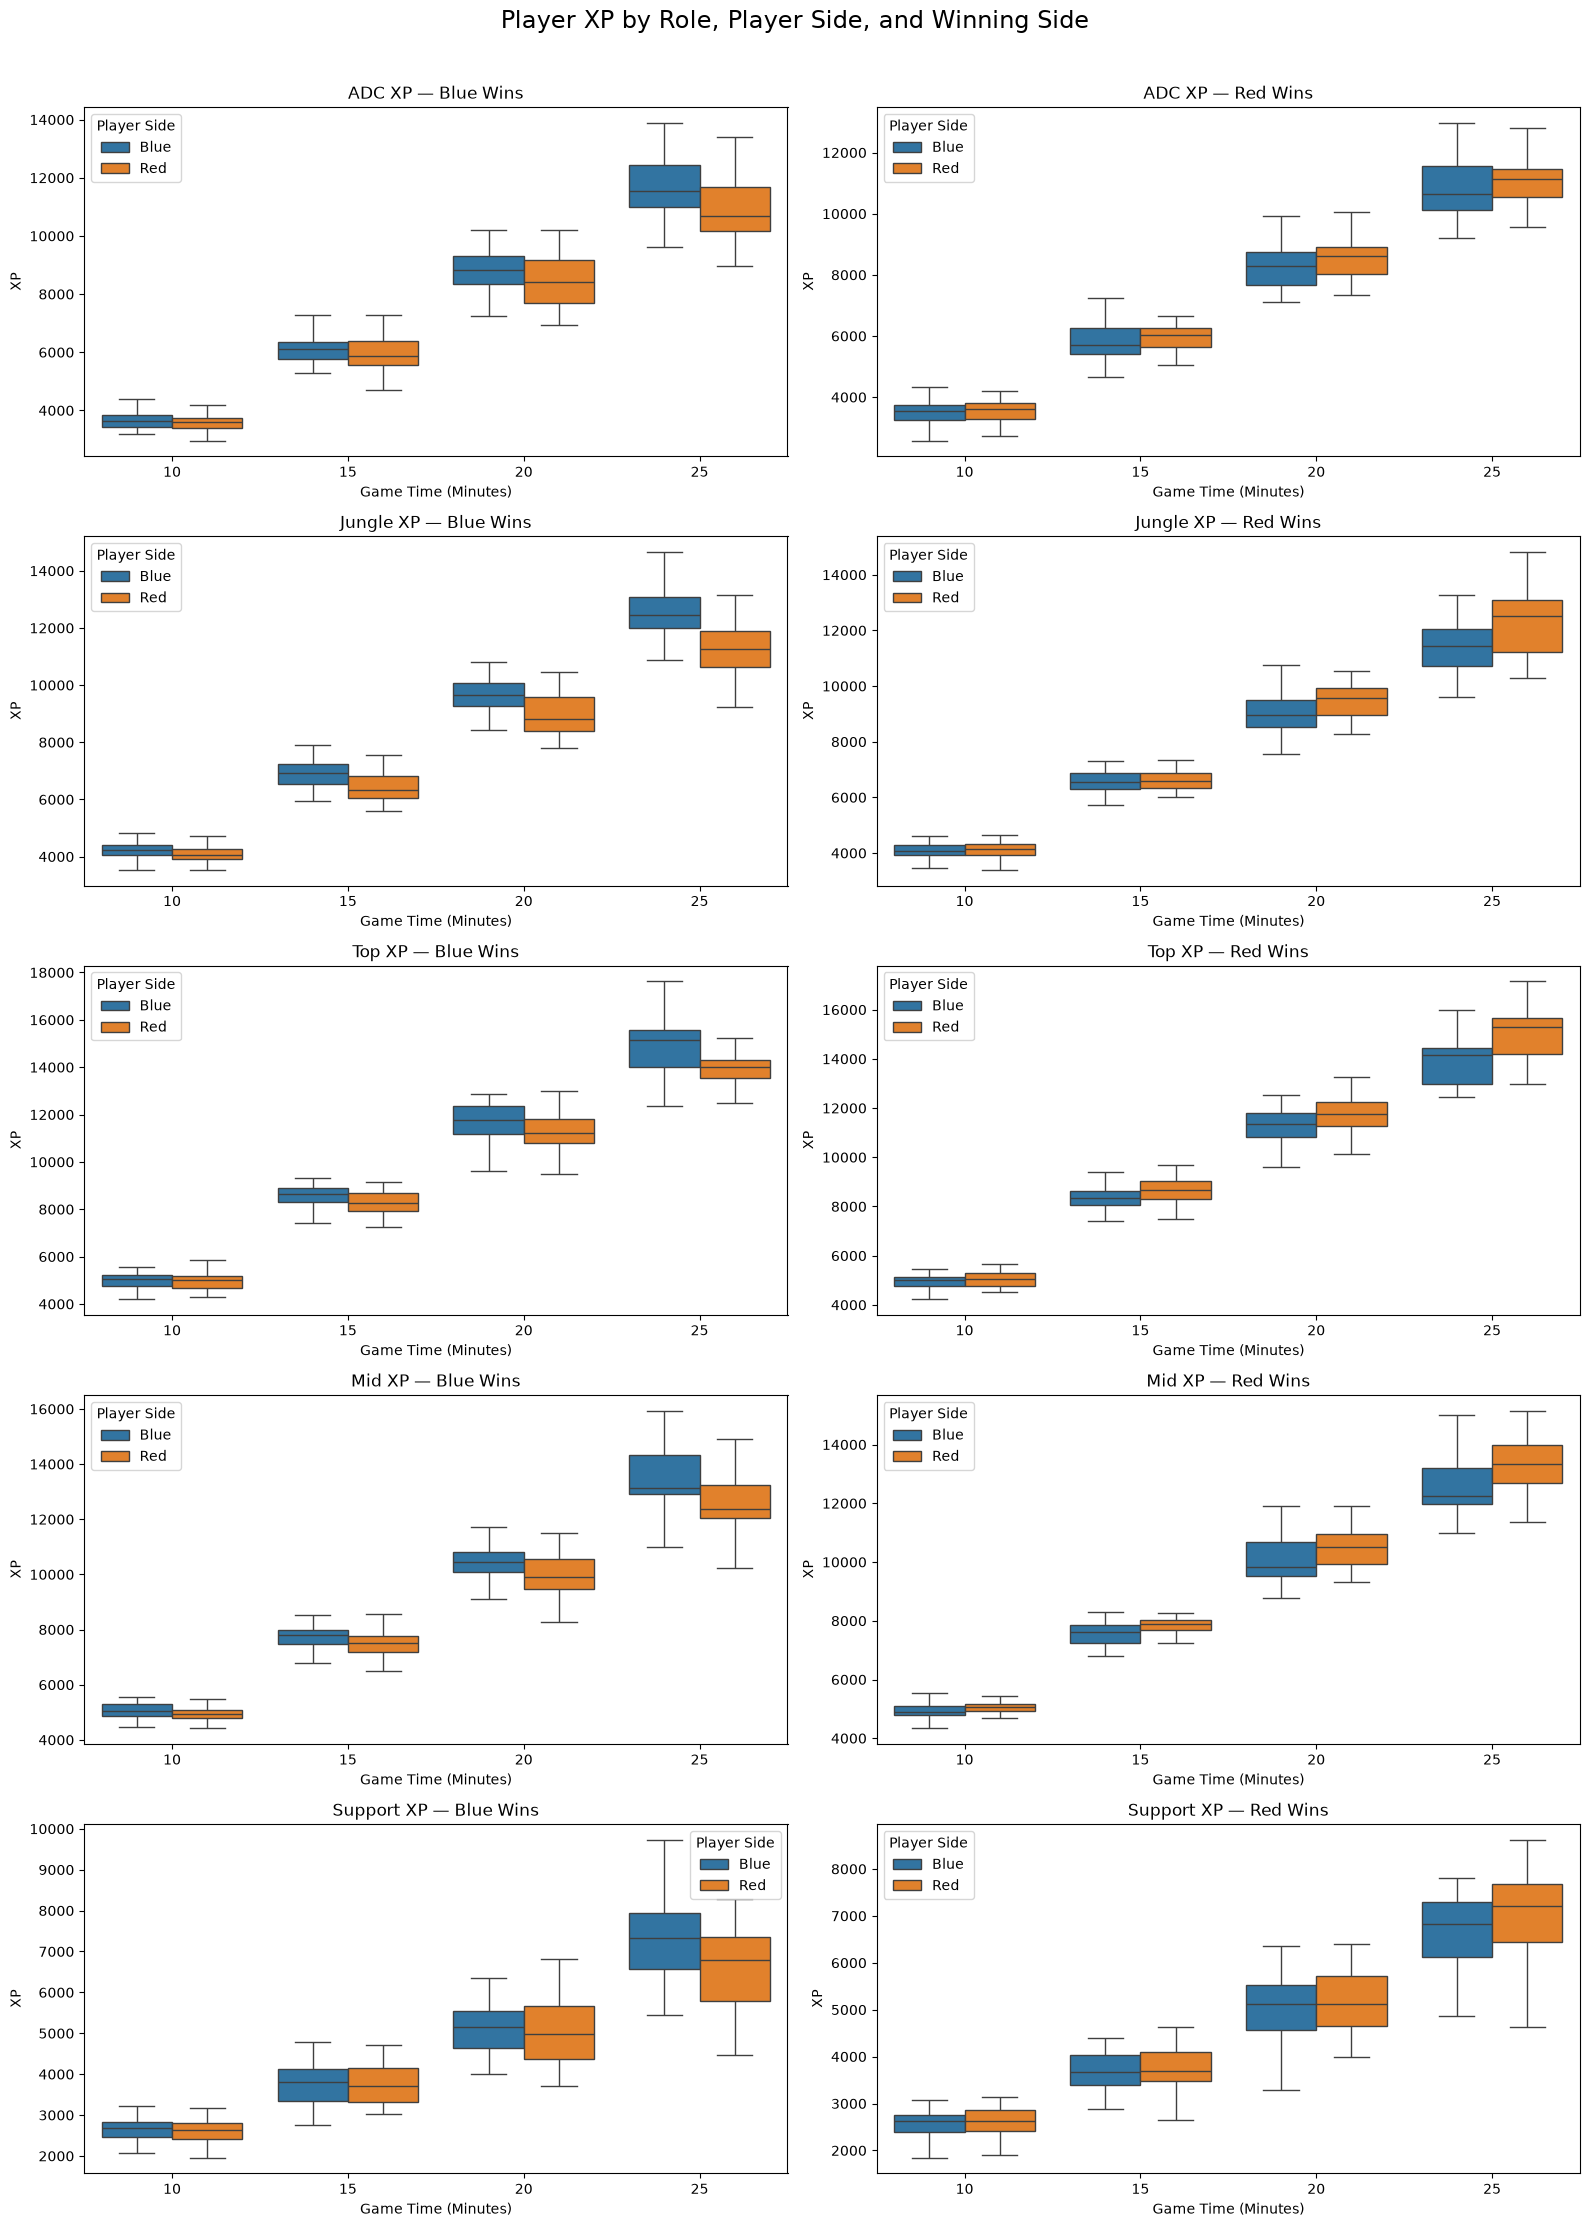

In [20]:
fig, axes = plt.subplots(5, 2, figsize=(16, 22))

winning_sides = ["Blue", "Red"]

for i, role in enumerate(roles):

    for j, winning_side in enumerate(winning_sides):

        ax = axes[i, j]

        role_data = player_xp_outcome[
            (player_xp_outcome["role"] == role) &
            (player_xp_outcome["winning_side"] == winning_side)
        ].copy()

        role_long = role_data.melt(
            id_vars=["side"],
            value_vars=xp_columns,
            var_name="game_time",
            value_name="XP"
        )

        role_long["game_time"] = role_long["game_time"].map({
            "xpat10": "10",
            "xpat15": "15",
            "xpat20": "20",
            "xpat25": "25"
        })

        sns.boxplot(
            data=role_long,
            x="game_time",
            y="XP",
            hue="side",
            order=["10", "15", "20", "25"],
            hue_order=["Blue", "Red"],
            showfliers=False,
            ax=ax
        )

        ax.set_title(f"{role} XP — {winning_side} Wins")
        ax.set_xlabel("Game Time (Minutes)")
        ax.set_ylabel("XP")
        ax.legend(title="Player Side")

fig.suptitle(
    "Player XP by Role, Player Side, and Winning Side",
    fontsize=17,
    y=1.01
)

plt.tight_layout()
plt.show()

In [21]:
from scipy.stats import ttest_rel, wilcoxon
from statsmodels.stats.multitest import multipletests

outcome_results = []

for winning_side in ["Blue", "Red"]:

    for role in roles:

        role_data = player_xp_outcome[
            (player_xp_outcome["role"] == role) &
            (player_xp_outcome["winning_side"] == winning_side)
        ].copy()

        for xp_col in xp_columns:

            # Separate XP by player side, indexed by game
            blue = (
                role_data[role_data["side"] == "Blue"]
                .set_index("gameid")[xp_col]
            )

            red = (
                role_data[role_data["side"] == "Red"]
                .set_index("gameid")[xp_col]
            )

            # Match Blue and Red players from the same game
            paired = pd.concat(
                [blue.rename("Blue"), red.rename("Red")],
                axis=1
            ).dropna()

            differences = paired["Blue"] - paired["Red"]

            # Paired t-test
            t_stat, t_pvalue = ttest_rel(
                paired["Blue"],
                paired["Red"]
            )

            # Wilcoxon signed-rank test
            if (differences != 0).any():
                w_stat, w_pvalue = wilcoxon(differences)
            else:
                w_stat, w_pvalue = 0, 1.0

            outcome_results.append({
                "winning_side": winning_side,
                "role": role,
                "snapshot": xp_col.replace("xpat", "") + " min",
                "n_games": len(paired),
                "blue_mean_xp": paired["Blue"].mean(),
                "red_mean_xp": paired["Red"].mean(),
                "mean_difference": differences.mean(),
                "t_statistic": t_stat,
                "t_pvalue": t_pvalue,
                "wilcoxon_pvalue": w_pvalue
            })

outcome_results_df = pd.DataFrame(outcome_results)

# Holm correction across all 40 comparisons
outcome_results_df["t_pvalue_holm"] = multipletests(
    outcome_results_df["t_pvalue"],
    method="holm"
)[1]

outcome_results_df["wilcoxon_pvalue_holm"] = multipletests(
    outcome_results_df["wilcoxon_pvalue"],
    method="holm"
)[1]

outcome_results_df["significant_ttest"] = (
    outcome_results_df["t_pvalue_holm"] < 0.05
)

outcome_results_df["significant_wilcoxon"] = (
    outcome_results_df["wilcoxon_pvalue_holm"] < 0.05
)

display(
    outcome_results_df.round(4)
)

,winning_side,role,snapshot,n_games,blue_mean_xp,red_mean_xp,mean_difference,t_statistic,t_pvalue,wilcoxon_pvalue,t_pvalue_holm,wilcoxon_pvalue_holm,significant_ttest,significant_wilcoxon
0,Blue,ADC,10 min,41,3643.4634,3599.6829,43.7805,0.7347,0.4668,0.5774,1.0000,1.0000,False,False
1,Blue,ADC,15 min,41,6089.7317,5963.3171,126.4146,1.2772,0.2089,0.2707,1.0000,1.0000,False,False
2,Blue,ADC,20 min,41,8766.5854,8468.1707,298.4146,2.3206,0.0255,0.0341,0.7138,0.8791,False,False
3,Blue,ADC,25 min,41,11625.7561,10893.8780,731.8780,3.9452,0.0003,0.0002,0.0116,0.0068,True,True
4,Blue,Jungle,10 min,41,4213.7317,4070.2927,143.4390,2.3157,0.0258,0.0271,0.7138,0.7601,False,False
5,Blue,Jungle,15 min,41,6910.3171,6419.9512,490.3659,4.0415,0.0002,0.0004,0.0089,0.0142,True,True
6,Blue,Jungle,20 min,41,9742.4634,9006.7073,735.7561,3.9382,0.0003,0.0009,0.0116,0.0315,True,True
7,Blue,Jungle,25 min,41,12660.3902,11276.7805,1383.6098,5.0144,0.0000,0.0000,0.0005,0.0013,True,True
8,Blue,Top,10 min,41,4968.6829,4938.2439,30.4390,0.3896,0.6989,0.7368,1.0000,1.0000,False,False
9,Blue,Top,15 min,41,8431.0000,8220.6098,210.3902,1.5365,0.1323,0.0481,1.0000,1.0000,False,False


In [22]:
significant_results = outcome_results_df[
    outcome_results_df["t_pvalue_holm"] < 0.05
].copy()

significant_results = significant_results.sort_values(
    ["winning_side", "role", "snapshot"]
)

display(significant_results.round(4))

,winning_side,role,snapshot,n_games,blue_mean_xp,red_mean_xp,mean_difference,t_statistic,t_pvalue,wilcoxon_pvalue,t_pvalue_holm,wilcoxon_pvalue_holm,significant_ttest,significant_wilcoxon
3,Blue,ADC,25 min,41,11625.7561,10893.8780,731.8780,3.9452,0.0003,0.0002,0.0116,0.0068,True,True
5,Blue,Jungle,15 min,41,6910.3171,6419.9512,490.3659,4.0415,0.0002,0.0004,0.0089,0.0142,True,True
6,Blue,Jungle,20 min,41,9742.4634,9006.7073,735.7561,3.9382,0.0003,0.0009,0.0116,0.0315,True,True
7,Blue,Jungle,25 min,41,12660.3902,11276.7805,1383.6098,5.0144,0.0000,0.0000,0.0005,0.0013,True,True
11,Blue,Top,25 min,41,14891.3415,13937.4390,953.9024,4.5286,0.0001,0.0001,0.0020,0.0027,True,True
31,Red,Top,25 min,29,14004.0000,15164.7931,-1160.7931,-3.8919,0.0006,0.0009,0.0196,0.0315,True,True


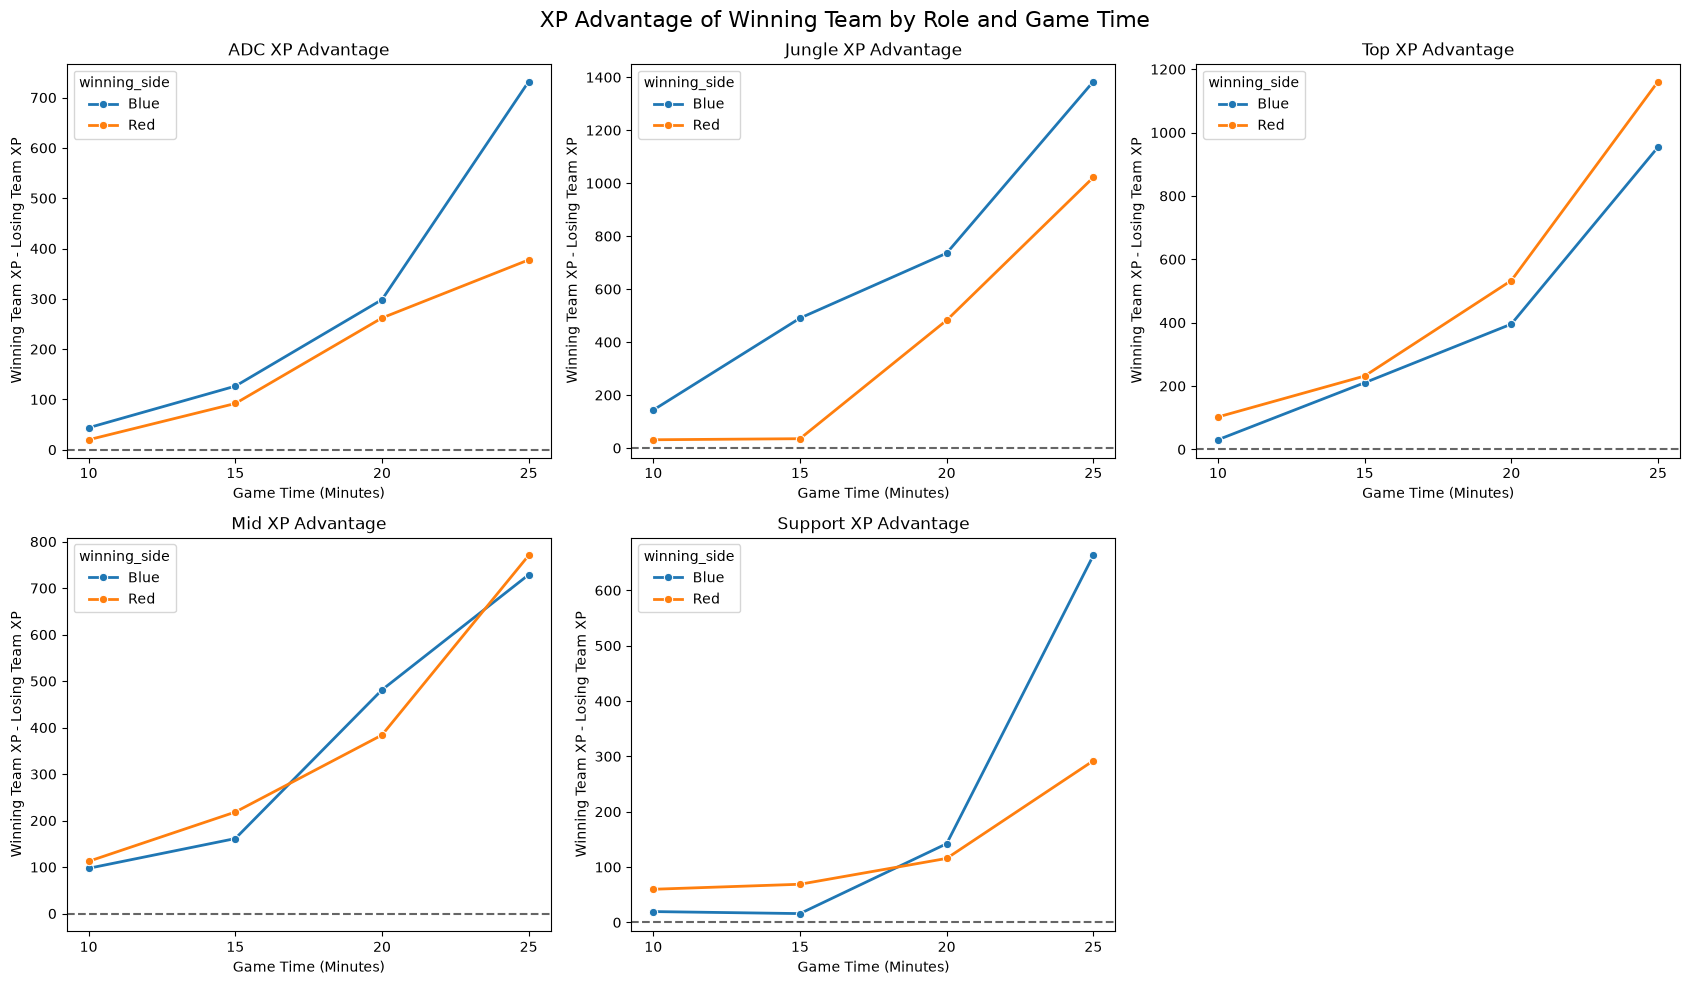

In [23]:
# Create a winning-team versus losing-team XP difference
winner_xp_results = []

for winning_side in ["Blue", "Red"]:
    for role in roles:

        role_data = player_xp_outcome[
            (player_xp_outcome["role"] == role) &
            (player_xp_outcome["winning_side"] == winning_side)
        ]

        for xp_col in xp_columns:

            blue = role_data[
                role_data["side"] == "Blue"
            ].set_index("gameid")[xp_col]

            red = role_data[
                role_data["side"] == "Red"
            ].set_index("gameid")[xp_col]

            paired = pd.concat(
                [blue.rename("Blue"), red.rename("Red")],
                axis=1
            ).dropna()

            # Calculate winning team XP minus losing team XP
            if winning_side == "Blue":
                difference = paired["Blue"] - paired["Red"]
            else:
                difference = paired["Red"] - paired["Blue"]

            winner_xp_results.append({
                "winning_side": winning_side,
                "role": role,
                "snapshot": int(xp_col.replace("xpat", "")),
                "mean_xp_advantage": difference.mean()
            })

winner_xp_df = pd.DataFrame(winner_xp_results)

# Plot
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
axes = axes.flatten()

for i, role in enumerate(roles):
    ax = axes[i]

    role_data = winner_xp_df[
        winner_xp_df["role"] == role
    ]

    sns.lineplot(
        data=role_data,
        x="snapshot",
        y="mean_xp_advantage",
        hue="winning_side",
        marker="o",
        linewidth=2,
        ax=ax
    )

    ax.axhline(0, color="black", linestyle="--", alpha=0.6)
    ax.set_title(f"{role} XP Advantage")
    ax.set_xlabel("Game Time (Minutes)")
    ax.set_ylabel("Winning Team XP - Losing Team XP")
    ax.set_xticks([10, 15, 20, 25])

fig.delaxes(axes[5])

fig.suptitle(
    "XP Advantage of Winning Team by Role and Game Time",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [24]:
#Why is jungle down in XP by 15 minutes for red side?

# Find all relevant CS and monster-kill columns
jungle_columns = [
    col for col in elixir_df.columns
    if (
        "csat" in col.lower()
        or "minion" in col.lower()
        or "monster" in col.lower()
    )
]

print("Relevant columns:")
print(jungle_columns)

Relevant columns:
['minionkills', 'monsterkills', 'monsterkillsownjungle', 'monsterkillsenemyjungle', 'csat10', 'opp_csat10', 'csat15', 'opp_csat15', 'csat20', 'opp_csat20', 'csat25', 'opp_csat25']


In [25]:
print(
    elixir_df["position"].value_counts()
)

position
top     144
jng     144
mid     144
bot     144
sup     144
team    144
Name: count, dtype: int64


In [26]:
# Keep jungle player rows only
jungle_df = player_xp_outcome[
    player_xp_outcome["role"] == "Jungle"
].copy()

# Variables to investigate
jungle_metrics = [
    "csat10",
    "csat15",
    "csat20",
    "csat25",
    "minionkills",
    "monsterkills",
    "monsterkillsownjungle"
]

# Preview available variables
display(
    jungle_df[
        ["gameid", "teamname", "side", "winning_side"]
        + [col for col in jungle_metrics if col in jungle_df.columns]
    ].head()
)

,gameid,teamname,side,winning_side,csat10,csat15,csat20,csat25,minionkills,monsterkills,monsterkillsownjungle
1,LOLTMNT02_482269,Invictus Gaming,Blue,Red,71.0,111.0,141.0,174.0,14.0,161,NaN
6,LOLTMNT02_482269,Gen.G,Red,Red,80.0,122.0,188.0,244.0,15.0,233,NaN
11,LOLTMNT02_483314,Top Esports,Blue,Red,86.0,120.0,147.0,NaN,11.0,152,NaN
16,LOLTMNT02_483314,Hanwha Life Esports,Red,Red,84.0,127.0,158.0,NaN,21.0,163,NaN
21,LOLTMNT02_483342,Movistar KOI,Blue,Blue,88.0,129.0,171.0,206.0,38.0,252,NaN


In [27]:
from scipy.stats import ttest_rel, wilcoxon
from statsmodels.stats.multitest import multipletests

# Variables to compare
jungle_metrics = [
    "csat10",
    "csat15",
    "csat20",
    "csat25",
    "minionkills",
    "monsterkills",
    "monsterkillsownjungle"
]

# Check that all requested columns exist
missing_columns = [
    col for col in jungle_metrics
    if col not in player_xp_outcome.columns
]

if missing_columns:
    print("Missing columns:", missing_columns)
else:
    print("All requested columns are available.")

# Keep jungle players
jungle_df = player_xp_outcome[
    player_xp_outcome["role"] == "Jungle"
].copy()

# Check for duplicate jungle observations per game and side
print("\nJungle observations per side:")
display(jungle_df.groupby("side")["gameid"].nunique())

print("\nMissing values:")
display(jungle_df[jungle_metrics].isna().sum())

All requested columns are available.

Jungle observations per side:


side
Blue    72
Red     72
Name: gameid, dtype: int64


Missing values:


csat10                     0
csat15                     0
csat20                     0
csat25                     4
minionkills                0
monsterkills               0
monsterkillsownjungle    144
dtype: int64

In [28]:
results = []

for winning_side in ["Blue", "Red"]:

    group = jungle_df[
        jungle_df["winning_side"] == winning_side
    ].copy()

    for metric in jungle_metrics:

        # Match Blue and Red junglers by game
        blue = (
            group[group["side"] == "Blue"]
            .set_index("gameid")[metric]
        )

        red = (
            group[group["side"] == "Red"]
            .set_index("gameid")[metric]
        )

        paired = pd.concat(
            [blue.rename("Blue"), red.rename("Red")],
            axis=1
        ).dropna()

        # Differences from the Blue team's perspective
        blue_minus_red = paired["Blue"] - paired["Red"]

        # Differences from the winning team's perspective
        if winning_side == "Blue":
            winner_minus_loser = blue_minus_red
        else:
            winner_minus_loser = -blue_minus_red

        # Paired t-test
        t_stat, t_p = ttest_rel(
            paired["Blue"],
            paired["Red"]
        )

        # Wilcoxon signed-rank test
        if (blue_minus_red != 0).any():
            w_stat, w_p = wilcoxon(blue_minus_red)
        else:
            w_stat, w_p = 0, 1.0

        results.append({
            "winning_side": winning_side,
            "metric": metric,
            "n_games": len(paired),
            "blue_mean": paired["Blue"].mean(),
            "red_mean": paired["Red"].mean(),
            "blue_minus_red": blue_minus_red.mean(),
            "winner_minus_loser": winner_minus_loser.mean(),
            "t_pvalue": t_p,
            "wilcoxon_pvalue": w_p
        })

jungle_results = pd.DataFrame(results)

# Holm correction across all 14 comparisons
jungle_results["t_pvalue_holm"] = multipletests(
    jungle_results["t_pvalue"],
    method="holm"
)[1]

jungle_results["wilcoxon_pvalue_holm"] = multipletests(
    jungle_results["wilcoxon_pvalue"],
    method="holm"
)[1]

jungle_results["significant"] = (
    jungle_results["t_pvalue_holm"] < 0.05
)

display(jungle_results.round(4))

C:\Users\boyle\AppData\Local\Temp\ipykernel_32196\237025978.py:37: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  t_stat, t_p = ttest_rel(
C:\Users\boyle\AppData\Local\Temp\ipykernel_32196\237025978.py:37: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  t_stat, t_p = ttest_rel(


,winning_side,metric,n_games,blue_mean,red_mean,blue_minus_red,winner_minus_loser,t_pvalue,wilcoxon_pvalue,t_pvalue_holm,wilcoxon_pvalue_holm,significant
0,Blue,csat10,41,80.7073,77.3171,3.3902,3.3902,0.0059,0.0067,0.0588,0.0672,False
1,Blue,csat15,41,124.5122,116.6585,7.8537,7.8537,0.0005,0.0005,0.0060,0.0066,True
2,Blue,csat20,41,167.0488,156.2439,10.8049,10.8049,0.0014,0.0023,0.0152,0.0249,True
3,Blue,csat25,41,203.8537,187.6098,16.2439,16.2439,0.0005,0.0007,0.0060,0.0086,True
4,Blue,minionkills,41,22.8537,22.8780,-0.0244,-0.0244,0.9898,0.9277,1.0000,1.0000,False
5,Blue,monsterkills,41,227.6585,200.4146,27.2439,27.2439,0.0000,0.0000,0.0001,0.0006,True
6,Blue,monsterkillsownjungle,0,NaN,NaN,NaN,NaN,NaN,1.0000,NaN,1.0000,False
7,Red,csat10,31,76.6452,78.4516,-1.8065,1.8065,0.2168,0.4042,1.0000,1.0000,False
8,Red,csat15,31,118.0968,119.8065,-1.7097,1.7097,0.5226,0.7912,1.0000,1.0000,False
9,Red,csat20,31,154.3871,162.1935,-7.8065,7.8065,0.0597,0.0844,0.4772,0.6754,False


In [29]:
display(
    jungle_results[
        jungle_results["significant"]
    ][
        [
            "winning_side",
            "metric",
            "n_games",
            "blue_minus_red",
            "winner_minus_loser",
            "t_pvalue_holm",
            "wilcoxon_pvalue_holm"
        ]
    ].round(4)
)

,winning_side,metric,n_games,blue_minus_red,winner_minus_loser,t_pvalue_holm,wilcoxon_pvalue_holm
1,Blue,csat15,41,7.8537,7.8537,0.0060,0.0066
2,Blue,csat20,41,10.8049,10.8049,0.0152,0.0249
3,Blue,csat25,41,16.2439,16.2439,0.0060,0.0086
5,Blue,monsterkills,41,27.2439,27.2439,0.0001,0.0006


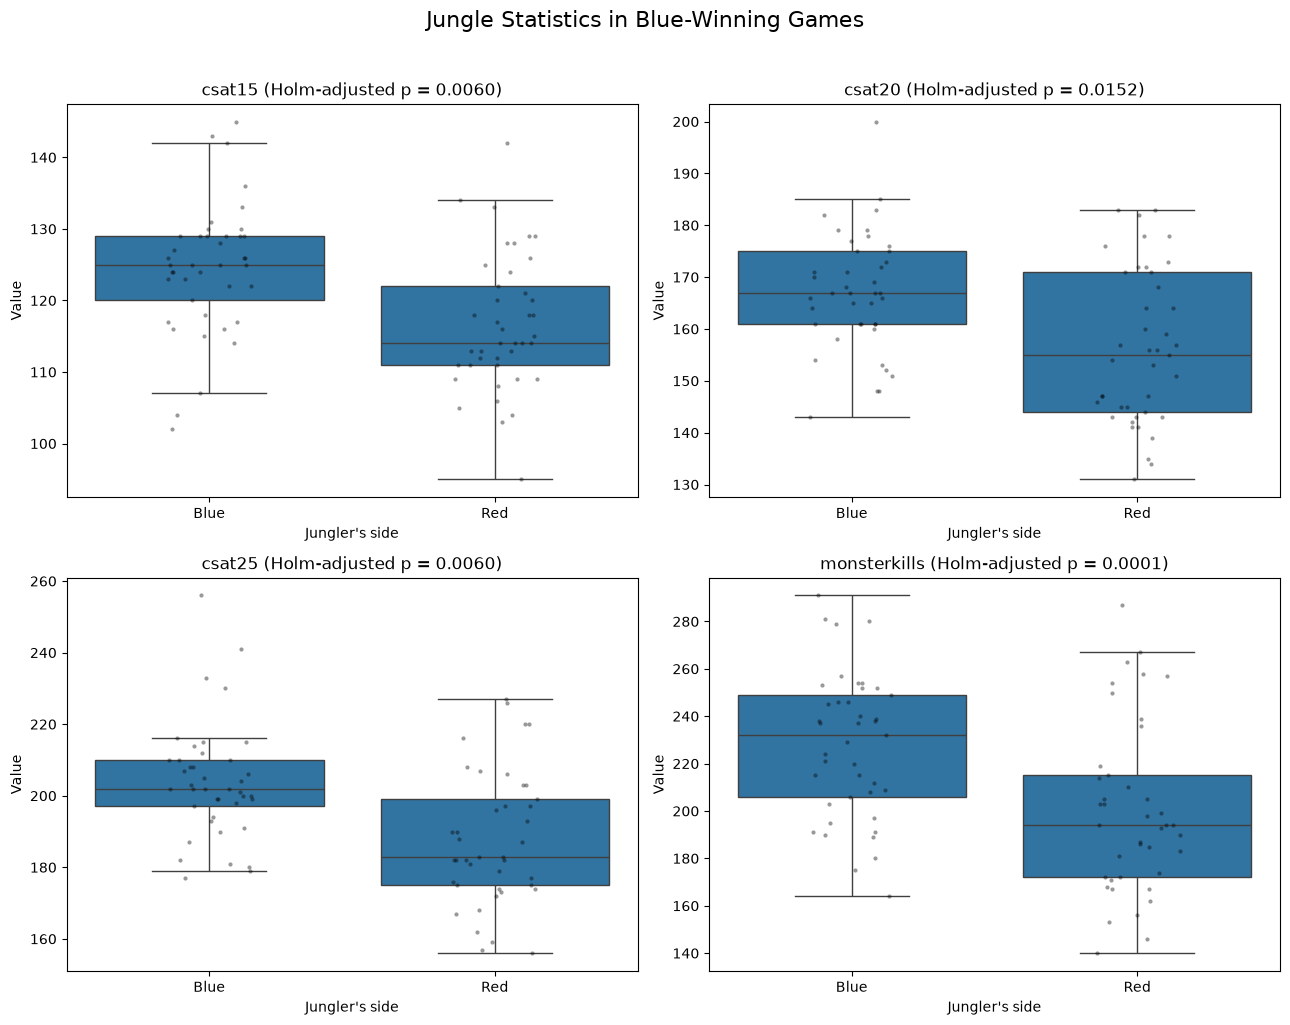

In [30]:
# Only the four significant metrics
significant_metrics = [
    "csat15",
    "csat20",
    "csat25",
    "monsterkills"
]

# Filter to Blue-winning games
blue_win_jungles = jungle_df[
    jungle_df["winning_side"] == "Blue"
].copy()

# Create 2x2 plots
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.flatten()

for i, metric in enumerate(significant_metrics):

    ax = axes[i]

    # Get adjusted p-value for this metric
    p_value = jungle_results.loc[
        (jungle_results["winning_side"] == "Blue") &
        (jungle_results["metric"] == metric),
        "t_pvalue_holm"
    ].iloc[0]

    sns.boxplot(
        data=blue_win_jungles,
        x="side",
        y=metric,
        order=["Blue", "Red"],
        showfliers=False,
        ax=ax
    )

    sns.stripplot(
        data=blue_win_jungles,
        x="side",
        y=metric,
        order=["Blue", "Red"],
        color="black",
        alpha=0.4,
        jitter=0.15,
        size=3,
        ax=ax
    )

    ax.set_title(
        f"{metric} (Holm-adjusted p = {p_value:.4f})"
    )
    ax.set_xlabel("Jungler's side")
    ax.set_ylabel("Value")

plt.suptitle(
    "Jungle Statistics in Blue-Winning Games",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()

In [31]:
# Get team-level observations
void_df = elixir_df[
    elixir_df["position"] == "team"
][
    ["gameid", "teamname", "side", "result", "void_grubs"]
].copy()

print("Missing values:")
print(void_df["void_grubs"].isna().sum())

print("\nVoid Grub count distribution:")
display(void_df["void_grubs"].value_counts().sort_index())

print("\nExample observations:")
display(void_df.head(10))

# Reshape into one row per game
void_games = void_df.pivot(
    index="gameid",
    columns="side",
    values="void_grubs"
).reset_index()

# Add winning side
void_games = void_games.merge(
    eda_games[["gameid", "winning_side"]],
    on="gameid",
    how="left",
    validate="one_to_one"
)

# Calculate the advantage from the winning team's perspective
void_games["blue_minus_red"] = (
    void_games["Blue"] - void_games["Red"]
)

void_games["winner_minus_loser"] = np.where(
    void_games["winning_side"] == "Blue",
    void_games["blue_minus_red"],
    -void_games["blue_minus_red"]
)

display(void_games.head(10))

Missing values:
0

Void Grub count distribution:


void_grubs
0.0    45
1.0    27
2.0    27
3.0    45
Name: count, dtype: int64


Example observations:


,gameid,teamname,side,result,void_grubs
10,LOLTMNT02_482269,Invictus Gaming,Blue,0,2.0
11,LOLTMNT02_482269,Gen.G,Red,1,1.0
22,LOLTMNT02_483314,Top Esports,Blue,0,3.0
23,LOLTMNT02_483314,Hanwha Life Esports,Red,1,0.0
34,LOLTMNT02_483342,Movistar KOI,Blue,1,3.0
35,LOLTMNT02_483342,Bilibili Gaming,Red,0,0.0
46,LOLTMNT02_482292,Karmine Corp,Blue,1,0.0
47,LOLTMNT02_482292,Anyone's Legend,Red,0,3.0
58,LOLTMNT02_482304,Dplus Kia,Blue,1,2.0
59,LOLTMNT02_482304,G2 Esports,Red,0,1.0


,gameid,Blue,Red,winning_side,blue_minus_red,winner_minus_loser
0,LOLTMNT02_482269,2.0,1.0,Red,1.0,-1.0
1,LOLTMNT02_482292,0.0,3.0,Blue,-3.0,-3.0
2,LOLTMNT02_482304,2.0,1.0,Blue,1.0,1.0
3,LOLTMNT02_482313,3.0,0.0,Red,3.0,-3.0
4,LOLTMNT02_482325,0.0,3.0,Red,-3.0,3.0
5,LOLTMNT02_482335,3.0,0.0,Blue,3.0,3.0
6,LOLTMNT02_482539,1.0,2.0,Blue,-1.0,-1.0
7,LOLTMNT02_482559,3.0,0.0,Blue,3.0,3.0
8,LOLTMNT02_482570,3.0,0.0,Red,3.0,-3.0
9,LOLTMNT02_482587,1.0,2.0,Red,-1.0,1.0


In [32]:
from scipy.stats import wilcoxon, binomtest

# Overall
overall = void_games["winner_minus_loser"].dropna()

overall_test = wilcoxon(overall)

print("OVERALL")
print("Mean winner advantage:", overall.mean())
print("Median winner advantage:", overall.median())
print("Wilcoxon p-value:", overall_test.pvalue)

# Blue-winning games
blue_wins = void_games[
    void_games["winning_side"] == "Blue"
]["blue_minus_red"].dropna()

blue_test = wilcoxon(blue_wins)

print("\nBLUE WINS")
print("Mean Blue advantage:", blue_wins.mean())
print("Median Blue advantage:", blue_wins.median())
print("Wilcoxon p-value:", blue_test.pvalue)

# Red-winning games
red_wins = void_games[
    void_games["winning_side"] == "Red"
]["blue_minus_red"].dropna()

red_test = wilcoxon(red_wins)

print("\nRED WINS")
print("Mean Blue advantage:", red_wins.mean())
print("Median Blue advantage:", red_wins.median())
print("Wilcoxon p-value:", red_test.pvalue)

OVERALL
Mean winner advantage: 0.3055555555555556
Median winner advantage: 1.0
Wilcoxon p-value: 0.2888807571949148

BLUE WINS
Mean Blue advantage: 0.7560975609756098
Median Blue advantage: 1.0
Wilcoxon p-value: 0.05620799138832713

RED WINS
Mean Blue advantage: 0.2903225806451613
Median Blue advantage: 1.0
Wilcoxon p-value: 0.48536498990562826


In [33]:
print("Void game rows:", len(void_games))

print("\nVoid Grub counts:")
print(void_games[["Blue", "Red"]].describe())

print("\nUnique Blue counts:")
print(sorted(void_games["Blue"].dropna().unique()))

print("\nUnique Red counts:")
print(sorted(void_games["Red"].dropna().unique()))

print("\nWinning side counts:")
print(void_games["winning_side"].value_counts())

print("\nWinner advantage:")
print(void_games["winner_minus_loser"].value_counts().sort_index())

Void game rows: 72

Void Grub counts:
            Blue        Red
count  72.000000  72.000000
mean    1.777778   1.222222
std     1.201199   1.201199
min     0.000000   0.000000
25%     1.000000   0.000000
50%     2.000000   1.000000
75%     3.000000   2.000000
max     3.000000   3.000000

Unique Blue counts:
[np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0)]

Unique Red counts:
[np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0)]

Winning side counts:
winning_side
Blue    41
Red     31
Name: count, dtype: int64

Winner advantage:
winner_minus_loser
-3.0    19
-1.0    13
 1.0    14
 3.0    26
Name: count, dtype: int64


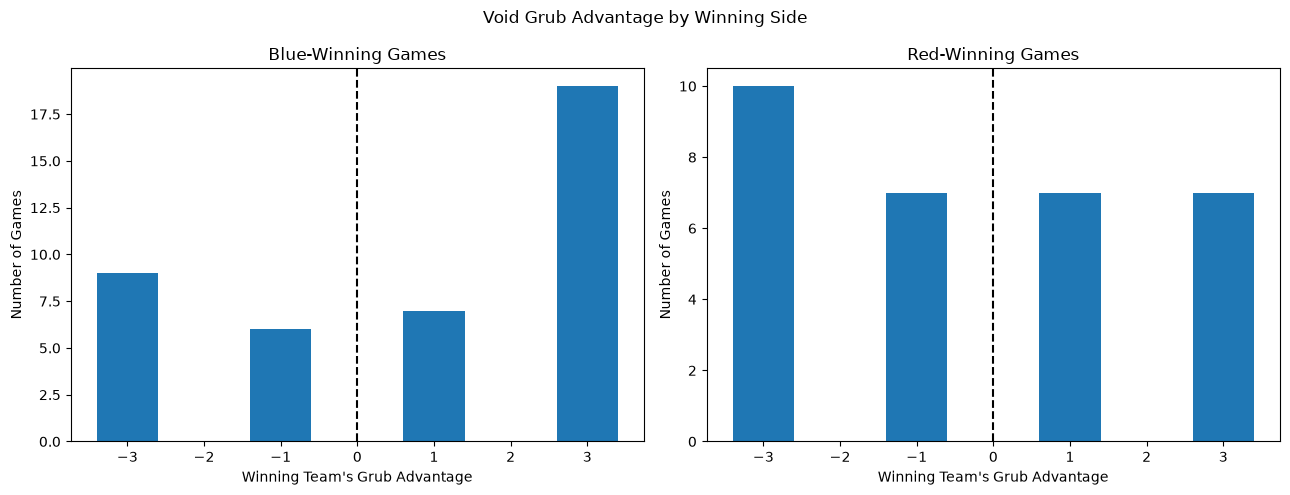

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

difference_values = [-3, -2, -1, 0, 1, 2, 3]

for ax, winning_side in zip(axes, ["Blue", "Red"]):

    subset = void_games.loc[
        void_games["winning_side"] == winning_side,
        "winner_minus_loser"
    ].dropna()

    counts = (
        subset.astype(int)
        .value_counts()
        .reindex(difference_values, fill_value=0)
    )

    ax.bar(counts.index, counts.values)

    ax.axvline(0, color="black", linestyle="--")
    ax.set_xticks(difference_values)
    ax.set_title(f"{winning_side}-Winning Games")
    ax.set_xlabel("Winning Team's Grub Advantage")
    ax.set_ylabel("Number of Games")

plt.suptitle("Void Grub Advantage by Winning Side")
plt.tight_layout()
plt.show()

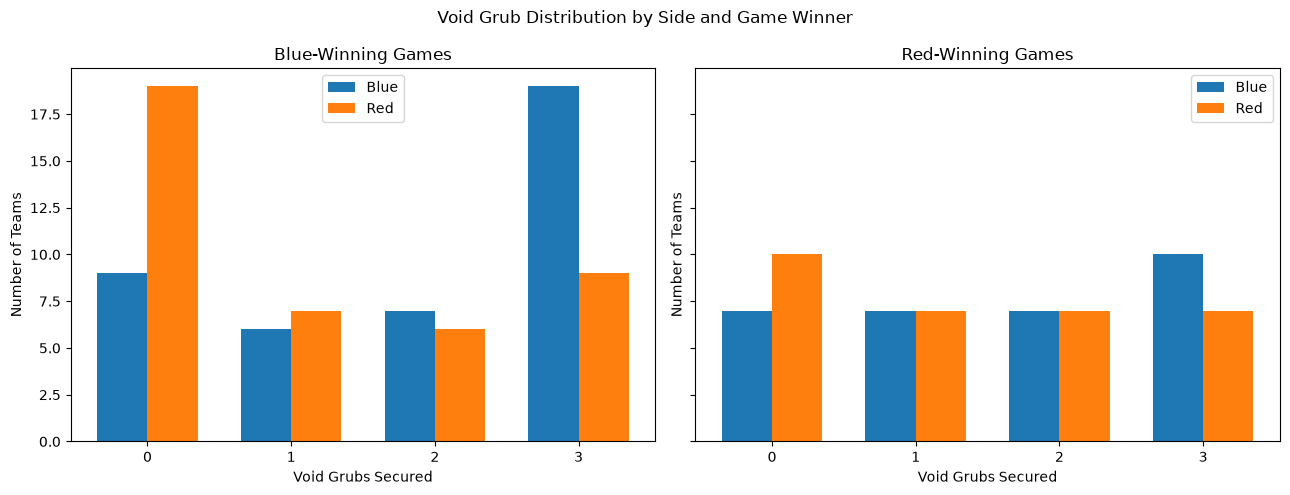

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

grub_values = [0, 1, 2, 3]

for ax, winning_side in zip(axes, ["Blue", "Red"]):

    subset = void_games[
        void_games["winning_side"] == winning_side
    ]

    blue_counts = (
        subset["Blue"].astype(int)
        .value_counts()
        .reindex(grub_values, fill_value=0)
    )

    red_counts = (
        subset["Red"].astype(int)
        .value_counts()
        .reindex(grub_values, fill_value=0)
    )

    x = np.arange(len(grub_values))
    width = 0.35

    ax.bar(x - width / 2, blue_counts.values, width, label="Blue")
    ax.bar(x + width / 2, red_counts.values, width, label="Red")

    ax.set_xticks(x)
    ax.set_xticklabels(grub_values)
    ax.set_xlabel("Void Grubs Secured")
    ax.set_ylabel("Number of Teams")
    ax.set_title(f"{winning_side}-Winning Games")
    ax.legend()

plt.suptitle("Void Grub Distribution by Side and Game Winner")
plt.tight_layout()
plt.show()

In [38]:
#Now lets look at games where void grubs were taken, and see if this contributes to junglers having more or less xp.

# Team-level Void Grub counts
void_counts = void_games[
    ["gameid", "Blue", "Red"]
].copy()

void_counts = void_counts.rename(
    columns={
        "Blue": "blue_void_grubs",
        "Red": "red_void_grubs"
    }
)

# Jungle XP at 15 minutes
jungle_xp15 = elixir_df[
    (elixir_df["position"] != "team") &
    (elixir_df["position"].str.lower().isin(["jng", "jgl"]))
][
    ["gameid", "side", "xpat15"]
].copy()

# Put Blue and Red junglers on the same row
jungle_wide = jungle_xp15.pivot(
    index="gameid",
    columns="side",
    values="xpat15"
).reset_index()

# Rename XP columns
jungle_wide = jungle_wide.rename(
    columns={
        "Blue": "blue_xp15",
        "Red": "red_xp15"
    }
)

# Add Void Grub counts
xp_gap = jungle_wide.merge(
    void_counts,
    on="gameid",
    how="left",
    validate="one_to_one"
)

# Calculate Blue minus Red XP
xp_gap["xp_gap_15"] = (
    xp_gap["blue_xp15"] -
    xp_gap["red_xp15"]
)

print("Number of games:", len(xp_gap))
display(xp_gap.head())

Number of games: 72


,gameid,blue_xp15,red_xp15,blue_void_grubs,red_void_grubs,xp_gap_15
0,LOLTMNT02_482269,6926.0,7211.0,2.0,1.0,-285.0
1,LOLTMNT02_482292,6920.0,6127.0,0.0,3.0,793.0
2,LOLTMNT02_482304,7261.0,6300.0,2.0,1.0,961.0
3,LOLTMNT02_482313,6569.0,7038.0,3.0,0.0,-469.0
4,LOLTMNT02_482325,5760.0,7302.0,0.0,3.0,-1542.0


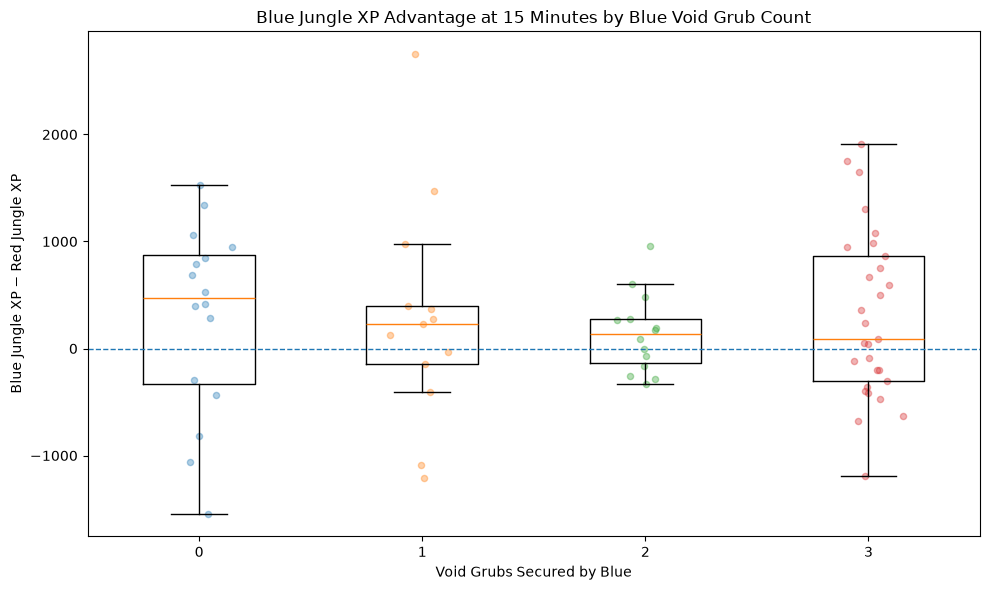

In [39]:
fig, ax = plt.subplots(figsize=(10, 6))

groups = [0, 1, 2, 3]
data = [
    xp_gap.loc[
        xp_gap["blue_void_grubs"] == grub,
        "xp_gap_15"
    ].dropna()
    for grub in groups
]

ax.boxplot(
    data,
    positions=groups,
    widths=0.5,
    showfliers=False
)

# Add individual observations
for grub, values in zip(groups, data):

    x_values = np.random.normal(
        grub,
        0.06,
        size=len(values)
    )

    ax.scatter(
        x_values,
        values,
        alpha=0.35,
        s=20
    )

ax.axhline(
    0,
    linestyle="--",
    linewidth=1
)

ax.set_xticks(groups)
ax.set_xlabel("Void Grubs Secured by Blue")
ax.set_ylabel("Blue Jungle XP − Red Jungle XP")
ax.set_title(
    "Blue Jungle XP Advantage at 15 Minutes by Blue Void Grub Count"
)

plt.tight_layout()
plt.show()

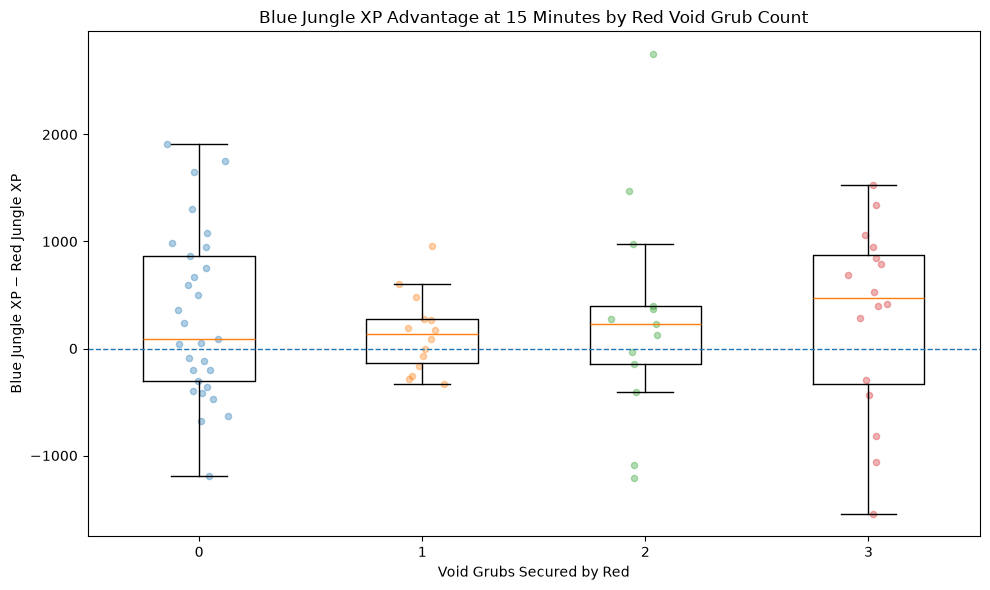

In [40]:
fig, ax = plt.subplots(figsize=(10, 6))

groups = [0, 1, 2, 3]

data = [
    xp_gap.loc[
        xp_gap["red_void_grubs"] == grub,
        "xp_gap_15"
    ].dropna()
    for grub in groups
]

ax.boxplot(
    data,
    positions=groups,
    widths=0.5,
    showfliers=False
)

for grub, values in zip(groups, data):

    x_values = np.random.normal(
        grub,
        0.06,
        size=len(values)
    )

    ax.scatter(
        x_values,
        values,
        alpha=0.35,
        s=20
    )

ax.axhline(
    0,
    linestyle="--",
    linewidth=1
)

ax.set_xticks(groups)
ax.set_xlabel("Void Grubs Secured by Red")
ax.set_ylabel("Blue Jungle XP − Red Jungle XP")
ax.set_title(
    "Blue Jungle XP Advantage at 15 Minutes by Red Void Grub Count"
)

plt.tight_layout()
plt.show()

In [41]:
# Summarize Blue Grubs vs XP gap

blue_grub_summary = (
    xp_gap
    .groupby("blue_void_grubs")["xp_gap_15"]
    .agg(
        n="count",
        mean="mean",
        median="median",
        std="std",
        min="min",
        max="max"
    )
    .reindex([0, 1, 2, 3])
)

display(blue_grub_summary.round(2))

,n,mean,median,std,min,max
blue_void_grubs,,,,,,
0,16,291.81,473.0,885.09,-1542.0,1527.0
1,13,283.31,225.0,1037.44,-1213.0,2749.0
2,14,138.00,132.5,368.89,-336.0,961.0
3,29,301.07,91.0,785.38,-1188.0,1913.0


In [42]:
from scipy.stats import kruskal

groups = [
    xp_gap.loc[
        xp_gap["blue_void_grubs"] == grub,
        "xp_gap_15"
    ].dropna()
    for grub in [0, 1, 2, 3]
]

kw_stat, kw_p = kruskal(*groups)

print("Kruskal–Wallis test")
print("--------------------")
print("H statistic:", round(kw_stat, 4))
print("p-value:", round(kw_p, 4))

Kruskal–Wallis test
--------------------
H statistic: 0.7963
p-value: 0.8504


In [43]:
#The groups may not be statsitcially significant in difference in xp gap but is the variance significant?

from scipy.stats import levene

# Separate XP-gap observations by Blue Void Grub count
groups = [
    xp_gap.loc[
        xp_gap["blue_void_grubs"] == grub,
        "xp_gap_15"
    ].dropna()
    for grub in [0, 1, 2, 3]
]

# Brown–Forsythe test
variance_stat, variance_p = levene(
    *groups,
    center="median"
)

print("Brown–Forsythe variance test")
print("----------------------------")
print("F statistic:", round(variance_stat, 4))
print("p-value:", round(variance_p, 4))

Brown–Forsythe variance test
----------------------------
F statistic: 1.9452
p-value: 0.1305


In [44]:
blue_grub_summary = (
    xp_gap
    .groupby("blue_void_grubs")["xp_gap_15"]
    .agg(
        n="count",
        mean="mean",
        median="median",
        std="std",
        variance="var",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75)
    )
    .reindex([0, 1, 2, 3])
)

blue_grub_summary["IQR"] = (
    blue_grub_summary["q75"] -
    blue_grub_summary["q25"]
)

display(blue_grub_summary.round(2))

,n,mean,median,std,variance,q25,q75,IQR
blue_void_grubs,,,,,,,,
0,16,291.81,473.0,885.09,783385.63,-332.5,872.50,1205.00
1,13,283.31,225.0,1037.44,1076274.06,-147.0,399.00,546.00
2,14,138.00,132.5,368.89,136076.62,-138.5,276.75,415.25
3,29,301.07,91.0,785.38,616824.85,-306.0,865.00,1171.00


In [45]:
from scipy.stats import spearmanr

trend_data = xp_gap[
    ["blue_void_grubs", "xp_gap_15"]
].dropna()

rho, p = spearmanr(
    trend_data["blue_void_grubs"],
    trend_data["xp_gap_15"]
)

print("Spearman correlation")
print("--------------------")
print("Correlation:", round(rho, 4))
print("P-value:", round(p, 4))

Spearman correlation
--------------------
Correlation: -0.046
P-value: 0.701


In [46]:
import pandas as pd
import numpy as np

from scipy.stats import kruskal, spearmanr, levene
from statsmodels.stats.multitest import multipletests

# Select Blue and Red jungle XP at 15, 20 and 25 minutes
jungle_xp = elixir_df[
    (elixir_df["position"].str.lower().isin(["jng", "jgl"]))
][
    ["gameid", "side", "xpat15", "xpat20", "xpat25"]
].copy()

# Put Blue and Red junglers on the same row
jungle_wide = jungle_xp.pivot(
    index="gameid",
    columns="side",
    values=["xpat15", "xpat20", "xpat25"]
)

# Flatten column names
jungle_wide.columns = [
    f"{metric}_{side.lower()}"
    for metric, side in jungle_wide.columns
]

jungle_wide = jungle_wide.reset_index()

# Calculate Blue-minus-Red XP gap at each interval
for minute in [15, 20, 25]:
    jungle_wide[f"xp_gap_{minute}"] = (
        jungle_wide[f"xpat{minute}_blue"] -
        jungle_wide[f"xpat{minute}_red"]
    )

# Add Void Grub counts
xp_gap_all = jungle_wide.merge(
    void_counts,
    on="gameid",
    how="left",
    validate="one_to_one"
)

print("Number of games:", len(xp_gap_all))
display(xp_gap_all.head())

Number of games: 72


,gameid,xpat15_blue,xpat15_red,xpat20_blue,xpat20_red,xpat25_blue,xpat25_red,xp_gap_15,xp_gap_20,xp_gap_25,blue_void_grubs,red_void_grubs
0,LOLTMNT02_482269,6926.0,7211.0,8868.0,11783.0,11018.0,16390.0,-285.0,-2915.0,-5372.0,2.0,1.0
1,LOLTMNT02_482292,6920.0,6127.0,9455.0,8572.0,12466.0,10734.0,793.0,883.0,1732.0,0.0,3.0
2,LOLTMNT02_482304,7261.0,6300.0,9216.0,8909.0,10920.0,11272.0,961.0,307.0,-352.0,2.0,1.0
3,LOLTMNT02_482313,6569.0,7038.0,9979.0,9812.0,12010.0,12813.0,-469.0,167.0,-803.0,3.0,0.0
4,LOLTMNT02_482325,5760.0,7302.0,8250.0,10555.0,9984.0,13962.0,-1542.0,-2305.0,-3978.0,0.0,3.0


In [47]:
results = []

for minute in [15, 20, 25]:

    gap_col = f"xp_gap_{minute}"

    # Remove missing observations
    data = xp_gap_all[
        ["blue_void_grubs", gap_col]
    ].dropna()

    # Separate games by Blue Grub count
    groups = [
        data.loc[
            data["blue_void_grubs"] == grub,
            gap_col
        ]
        for grub in [0, 1, 2, 3]
    ]

    # 1. Kruskal-Wallis: distribution differences
    kw_stat, kw_p = kruskal(*groups)

    # 2. Brown-Forsythe: variance differences
    bf_stat, bf_p = levene(
        *groups,
        center="median"
    )

    # 3. Spearman: monotonic trend
    rho, spearman_p = spearmanr(
        data["blue_void_grubs"],
        data[gap_col]
    )

    results.append({
        "minute": minute,
        "n": len(data),
        "KW_stat": kw_stat,
        "KW_p": kw_p,
        "BF_stat": bf_stat,
        "BF_p": bf_p,
        "Spearman_rho": rho,
        "Spearman_p": spearman_p
    })

results_df = pd.DataFrame(results)

# Holm correction across the three time intervals
# Separately for each test family
for test in ["KW", "BF", "Spearman"]:

    results_df[f"{test}_p_holm"] = multipletests(
        results_df[f"{test}_p"],
        method="holm"
    )[1]

display(results_df.round(4))

,minute,n,KW_stat,KW_p,BF_stat,BF_p,Spearman_rho,Spearman_p,KW_p_holm,BF_p_holm,Spearman_p_holm
0,15,72,0.7963,0.8504,1.9452,0.1305,-0.0460,0.7010,1.0,0.3916,0.857
1,20,72,1.2781,0.7343,0.9662,0.4139,0.0948,0.4285,1.0,0.8277,0.857
2,25,70,2.9307,0.4024,0.1584,0.9239,0.1449,0.2313,1.0,0.9239,0.694


In [48]:
summary_results = []

for minute in [15, 20, 25]:

    gap_col = f"xp_gap_{minute}"

    summary = (
        xp_gap_all
        .groupby("blue_void_grubs")[gap_col]
        .agg(
            n="count",
            mean="mean",
            median="median",
            std="std",
            q25=lambda x: x.quantile(0.25),
            q75=lambda x: x.quantile(0.75)
        )
        .reindex([0, 1, 2, 3])
        .reset_index()
    )

    summary["minute"] = minute
    summary["IQR"] = summary["q75"] - summary["q25"]

    summary_results.append(summary)

summary_df = pd.concat(
    summary_results,
    ignore_index=True
)

display(summary_df.round(2))

,blue_void_grubs,n,mean,median,std,q25,q75,minute,IQR
0,0,16,291.81,473.0,885.09,-332.50,872.50,15,1205.00
1,1,13,283.31,225.0,1037.44,-147.00,399.00,15,546.00
2,2,14,138.00,132.5,368.89,-138.50,276.75,15,415.25
3,3,29,301.07,91.0,785.38,-306.00,865.00,15,1171.00
4,0,16,130.38,517.0,1385.09,-968.50,1137.75,20,2106.25
5,1,13,90.92,-68.0,1690.50,-919.00,569.00,20,1488.00
6,2,14,-109.36,48.5,1037.78,-527.00,678.00,20,1205.00
7,3,29,464.69,167.0,1386.31,-476.00,1693.00,20,2169.00
8,0,16,341.25,-50.5,2319.86,-696.50,1636.75,25,2333.25
9,1,13,132.31,-83.0,2368.52,-764.00,1127.00,25,1891.00


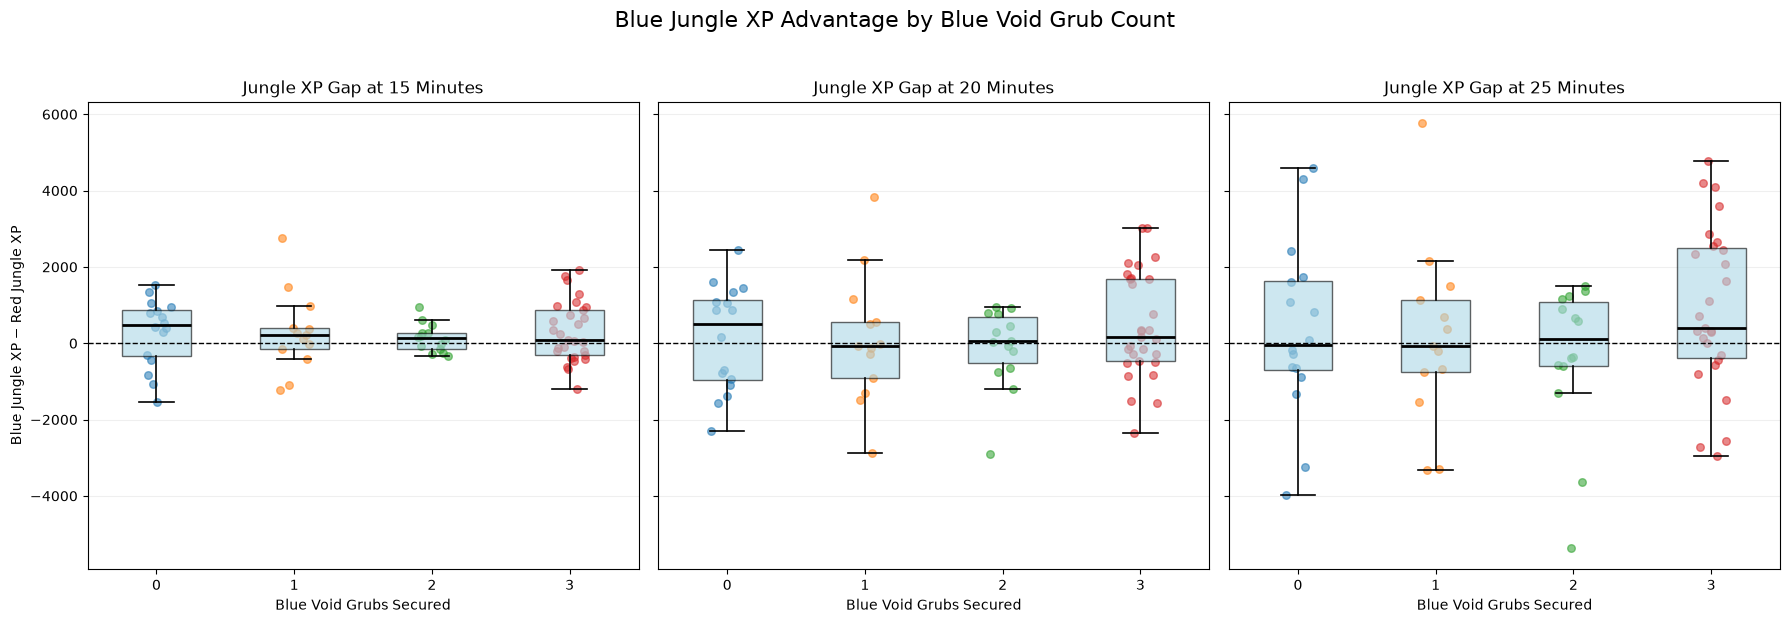

In [49]:
import matplotlib.pyplot as plt
import numpy as np

minutes = [15, 20, 25]
grub_counts = [0, 1, 2, 3]

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6),
    sharey=True
)

for ax, minute in zip(axes, minutes):

    gap_col = f"xp_gap_{minute}"

    plot_groups = [
        xp_gap_all.loc[
            xp_gap_all["blue_void_grubs"] == grub,
            gap_col
        ].dropna()
        for grub in grub_counts
    ]

    # Boxplots
    ax.boxplot(
        plot_groups,
        positions=grub_counts,
        widths=0.5,
        patch_artist=True,
        showfliers=False,
        medianprops={"color": "black", "linewidth": 2},
        boxprops={"facecolor": "lightblue", "alpha": 0.6},
        whiskerprops={"linewidth": 1.2},
        capprops={"linewidth": 1.2}
    )

    # Individual observations with jitter
    for grub, values in zip(grub_counts, plot_groups):

        jitter = np.random.uniform(
            -0.12, 0.12, size=len(values)
        )

        ax.scatter(
            grub + jitter,
            values,
            alpha=0.55,
            s=30
        )

    # Zero reference line
    ax.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=1
    )

    ax.set_title(f"Jungle XP Gap at {minute} Minutes")
    ax.set_xlabel("Blue Void Grubs Secured")
    ax.set_xticks(grub_counts)
    ax.grid(axis="y", alpha=0.2)

axes[0].set_ylabel(
    "Blue Jungle XP − Red Jungle XP"
)

fig.suptitle(
    "Blue Jungle XP Advantage by Blue Void Grub Count",
    fontsize=16,
    y=1.03
)

plt.tight_layout()
plt.show()